# What makes a music artist successful?
### Using data to understand what makes artists popular on major music streaming platforms
**Programming for Data Science 2026/2027 · Group Project · Group XX**

| Name | Student number |
|---|---|
| Sergio Kuts Pires | 20251282 |
| _Member 2_ | _number_ |
| _Member 3_ | _number_ |
| _Member 4_ | _number_ |

**GitHub repository (used during development):** _add the public link here_

## Contents
0. [Setup](#0.-Setup)
1. [Data Wrangling and Analysis](#1.-Data-Wrangling-and-Analysis)
   - [Q1 · Data quality](#Q1-·-Data-quality) · [Q2 · Who is in the data](#Q2-·-Who-is-in-the-data) · [Q3 · Update dates](#Q3-·-Update-dates) · [Q4 · Career length and collaborations](#Q4-·-Career-length-and-collaborations) · [Q5 · Additional insights](#Q5-·-Additional-insights)
2. [Advanced Topic: Interactive Maps](#2.-Advanced-Topic:-Interactive-Maps)
   - [2.1 Web scraping Wikipedia](#2.1-Web-scraping-Wikipedia) · [2.2 Checking the matches](#2.2-Checking-the-matches) · [2.3 Interactive maps](#2.3-Interactive-maps)
3. [Data Science in Action: the Success Lab](#3.-Data-Science-in-Action:-the-Success-Lab)
   - [3.1 New variables](#3.1-New-variables) · [3.2 What moves with streams?](#3.2-What-moves-with-streams?) · [3.3 Artist archetypes](#3.3-Artist-archetypes) · [3.4 Stream estimator](#3.4-Stream-estimator) · [3.5 Artist comparison tool](#3.5-Artist-comparison-tool)
4. [Conclusions](#4.-Conclusions)

**How to run:** keep `artist_streams.csv` and the `data/` folder next to this notebook and run all cells from top to bottom (about 1–2 minutes).
Tested with Python 3.14, pandas 3.0, plotly 6.7 (`density_map` needs plotly 5.24 or newer), seaborn 0.13 and scikit-learn 1.9 (exact versions printed below).
The full Wikipedia scrape takes about 20 minutes, so by default the notebook loads the results we saved in `data/wikipedia_locations.csv`
(set `RUN_FULL_SCRAPE = True` in section 2.1 to scrape everything again). Figures and maps are also saved to `outputs/`.

## 0. Setup

In [1]:
# --- Standard library ---
import re
import time
import difflib
import platform
import unicodedata
import warnings
from pathlib import Path
from urllib.parse import urljoin, unquote

# --- Data handling and statistics ---
import numpy as np
import pandas as pd
import scipy
from scipy import stats

# --- Visualisation ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# --- Web scraping ---
import requests
import bs4
from bs4 import BeautifulSoup

# --- Machine learning (Data Science in Action) ---
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import RepeatedKFold, KFold, cross_validate, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Interactive controls (optional: only used for the estimator in 3.4) ---
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)

The brief asks us to show the version of every package we use:

In [2]:
versions = {
    'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
    'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
    'plotly': plotly.__version__, 'requests': requests.__version__, 'beautifulsoup4': bs4.__version__,
    'scikit-learn': sklearn.__version__, 'ipywidgets': widgets.__version__ if widgets else 'not installed',
}
pd.Series(versions, name='version').to_frame()

,version
python,3.14.6
pandas,3.0.6
numpy,2.5.3
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2
plotly,7.1.0
requests,2.34.2
beautifulsoup4,4.15.0
scikit-learn,1.9.1


In [3]:
# --- Paths ---
DATA_FILE = Path('artist_streams.csv')
WIKI_CACHE = Path('data') / 'wikipedia_locations.csv'      # saved results of the Wikipedia scrape (section 2.1)
OUT_DIR = Path('outputs')
FIG_DIR, MAP_DIR = OUT_DIR / 'figures', OUT_DIR / 'maps'
for folder in (WIKI_CACHE.parent, FIG_DIR, MAP_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- One colour system for every chart ---
SURFACE, INK, INK_2, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'      # categorical slots 1-3 (colour-blind checked)
GRAY = '#c3c2b7'                                            # "everything else"
RED = '#e34948'                                             # opposite pole of diverging scales
SEQ_BLUES = ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b']   # light -> dark

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12.5, 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'font.size': 10.5, 'figure.dpi': 110, 'legend.frameon': False,
})

# Plotly: same colours, light background
pio.templates['pds'] = go.layout.Template(layout=dict(
    font=dict(family='Segoe UI, system-ui, sans-serif', color=INK_2, size=12),
    paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, colorway=[BLUE, ORANGE, AQUA, GRAY],
    title=dict(font=dict(color=INK, size=17), x=0.01, xanchor='left'),
    xaxis=dict(gridcolor=GRID, linecolor=GRAY, zeroline=False),
    yaxis=dict(gridcolor=GRID, linecolor=GRAY, zeroline=False),
    hoverlabel=dict(bgcolor='white', font_size=12),
))
pio.templates.default = 'simple_white+pds'
pio.renderers.default = 'plotly_mimetype+notebook_connected'   # JupyterLab, classic Jupyter and VS Code (plotly.js loaded online)


def save(fig, name):
    """Save a matplotlib figure in outputs/figures (we reuse them in the presentation)."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')


def billions(x):
    """Streams are stored in millions; 137492.1 -> '137.5B'."""
    return f'{x / 1000:,.1f}B'

## 1. Data Wrangling and Analysis

Each row of `artist_streams.csv` is one artist of the platform's all-time most-streamed list. Stream columns are in **millions**
(so `137492.1` = 137.5 billion streams). We first look at the raw file, then clean it step by step, and only then answer the questions.

In [4]:
raw = pd.read_csv(DATA_FILE)
print(f'{raw.shape[0]} rows x {raw.shape[1]} columns')
raw.head()

511 rows x 15 columns


,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist ID              511 non-null    int64  
 1   Artist Name            510 non-null    str    
 2   Sex                    486 non-null    str    
 3   Country of Origin      510 non-null    str    
 4   Primary Language       510 non-null    str    
 5   Primary Genre          510 non-null    str    
 6   Artist Type            510 non-null    str    
 7   Debut Year             510 non-null    float64
 8   Total Streams          505 non-null    float64
 9   Lead Streams           504 non-null    float64
 10  Feature Streams        499 non-null    float64
 11  Solo Streams           506 non-null    float64
 12  Collaborative Streams  509 non-null    float64
 13  Update Date            510 non-null    str    
 14  Year                   510 non-null    float64
dtypes: float64(7), in

First impressions: 511 rows but `Artist ID` only goes up to 500, so something is repeated; most columns have at least one missing value;
`Debut Year` and `Year` are stored as decimals (`2006.0`) and `Update Date` as text. We go through every issue below.

### Q1 · Data quality
*Are there duplicates or missing values? How did we handle them? Any other data quality issues?*

We check, in this order: **(1)** duplicates, **(2)** empty records, **(3)** missing values and how to fill them,
**(4)** inconsistent categories, **(5)** data types, **(6)** values that are impossible or suspicious.

#### 1.1 Duplicates

In [6]:
print('Exact duplicate rows:', raw.duplicated().sum())
raw[raw.duplicated(keep=False)].sort_values('Artist ID')[['Artist ID', 'Artist Name', 'Total Streams', 'Update Date']]

Exact duplicate rows: 10


,Artist ID,Artist Name,Total Streams,Update Date
45,45,Linkin Park,33224.7,2026-07-01 00:00:00
46,45,Linkin Park,33224.7,2026-07-01 00:00:00
141,140,Fleetwood Mac,16577.5,2026-07-01 00:00:00
142,140,Fleetwood Mac,16577.5,2026-07-01 00:00:00
220,218,John Mayer,13208.3,2026-07-01 00:00:00
221,218,John Mayer,13208.3,2026-07-01 00:00:00
224,221,System Of A Down,13009.4,2026-07-01 00:00:00
225,221,System Of A Down,13009.4,2026-07-01 00:00:00
267,263,Zedd,11481.4,2026-07-01 00:00:00
268,263,Zedd,11481.4,2026-07-01 00:00:00


In [7]:
df = raw.drop_duplicates().copy()

# After removing the exact copies, is any artist still listed twice - under the same ID,
# or under a name written slightly differently (case, accents, punctuation)?
name_key = (df['Artist Name'].str.lower().str.normalize('NFKD')
            .str.encode('ascii', 'ignore').str.decode('ascii')
            .str.replace(r'[^a-z0-9]', '', regex=True))
print('Rows left                :', len(df))
print('Repeated Artist ID       :', df['Artist ID'].duplicated().sum())
print('Repeated (normalised) name:', name_key.dropna().duplicated().sum())

Rows left                : 501
Repeated Artist ID       : 0
Repeated (normalised) name: 0


**Decision:** the 10 duplicated rows are identical in *every* column, including `Artist ID`, so they are the same record entered twice.
We keep one copy of each. Keeping both would count these 10 artists twice in every total, count and average.
No other artist appears twice, even when we compare names without case, accents or punctuation. (*Macklemore & Ryan Lewis* and *Ryan Lewis* are both in the list, but they are different credits, the duo and one of its members, not duplicates.)

#### 1.2 Empty records

In [8]:
value_cols = df.columns.drop('Artist ID')
empty_rows = df[value_cols].isna().all(axis=1)
display(df[empty_rows])
df = df[~empty_rows].copy()
print('Rows left:', len(df))

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
510,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Rows left: 500


**Decision:** `Artist ID` 500 has an ID and nothing else (no name, no streams), so it cannot be used for anything. We remove it.
We now have **500 rows with 500 different IDs (0 to 499)**.

#### 1.3 Missing values

In [9]:
missing = df.isna().sum()
pd.DataFrame({'missing': missing, '% of rows': (missing / len(df) * 100).round(1)}).query('missing > 0')

,missing,% of rows
Sex,22,4.4
Total Streams,5,1.0
Lead Streams,6,1.2
Feature Streams,9,1.8
Solo Streams,4,0.8
Collaborative Streams,1,0.2


Two kinds of gaps are left: **stream counts** (25 values) and **Sex** (22 values).

**Stream counts.** The brief says that `Total = Solo + Collaborative` and `Total = Lead + Feature`.
If these rules hold, a missing value does not have to be guessed, it can be **computed** from the other columns. We first check how well each rule holds on the complete rows:

In [10]:
STREAMS = ['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']

gap_solo_collab = df['Total Streams'] - (df['Solo Streams'] + df['Collaborative Streams'])
gap_lead_feat = df['Total Streams'] - (df['Lead Streams'] + df['Feature Streams'])
pd.DataFrame({
    'Total - (Solo + Collab)': gap_solo_collab.describe(),
    'Total - (Lead + Feature)': gap_lead_feat.describe(),
    'Total - (Lead + Feature), % of Total': (gap_lead_feat / df['Total Streams'] * 100).describe(),
}).round(3)

,Total - (Solo + Collab),Total - (Lead + Feature),"Total - (Lead + Feature), % of Total"
count,490.0,480.000,480.000
mean,-0.0,-5.367,-0.041
std,0.0,9.369,0.071
min,-0.0,-39.200,-0.388
25%,0.0,-9.150,-0.056
50%,0.0,-5.000,-0.035
75%,0.0,-1.275,-0.011
max,0.0,89.200,0.545


- `Total = Solo + Collaborative` holds **exactly** for every complete row (the gap is 0.000).
- `Total = Lead + Feature` holds only **approximately**: Lead + Feature is usually a little *larger* than Total (median gap 0.035 %, never more than 0.6 %).
  This is a small inconsistency in the data itself. It is too small to matter for the analysis, but it means values filled with this rule are approximations.

No row is missing more than one value of the same rule, so we can fill everything:
* `Total`, `Solo`, `Collaborative` with the **exact** rule;
* `Lead`, `Feature` with the approximate rule, never going below 0 (e.g. Harry Styles' missing Feature would be -13.8, which is impossible, so it becomes 0. This is consistent with his 0 collaborative streams).

This is better than filling with the mean or median, which would ignore the information we have about that specific artist. (None of our answers uses the filled Lead/Feature values: we measure collaboration with Solo/Collaborative, see 1.6.)

In [11]:
was_missing = df[STREAMS].isna()          # remember what we fill, to show it below
print('Rows missing more than one stream value:', (was_missing.sum(axis=1) > 1).sum())

total, lead, feat, solo, collab = (df[c] for c in STREAMS)
df['Total Streams'] = total.fillna(solo + collab)                                      # exact rule
df['Solo Streams'] = solo.fillna(df['Total Streams'] - collab)                         # exact rule
df['Collaborative Streams'] = collab.fillna(df['Total Streams'] - df['Solo Streams'])  # exact rule
df['Lead Streams'] = lead.fillna((df['Total Streams'] - feat).clip(lower=0))           # approximate rule
df['Feature Streams'] = feat.fillna((df['Total Streams'] - df['Lead Streams']).clip(lower=0))
df[STREAMS] = df[STREAMS].round(1)                                                     # same precision as the file
print('Missing stream values left:', df[STREAMS].isna().sum().sum())
harry = raw.set_index('Artist Name').loc['Harry Styles']
print(f"Example of the floor at 0: Harry Styles' Feature by the rule would be {harry['Total Streams'] - harry['Lead Streams']:.1f} M -> set to 0")

filled = [{'Artist': df.at[i, 'Artist Name'], 'Filled column': col, 'Value (M)': df.at[i, col]}
          for col in STREAMS for i in df.index[was_missing[col]]]
pd.DataFrame(filled)

Rows missing more than one stream value: 0
Missing stream values left: 0


Example of the floor at 0: Harry Styles' Feature by the rule would be -13.8 M -> set to 0


,Artist,Filled column,Value (M)
0,Peso Pluma,Total Streams,33179.8
1,blink-182,Total Streams,10760.4
2,Fetty Wap,Total Streams,8564.5
3,Thomas Rhett,Total Streams,7337.5
4,Ryan Lewis,Total Streams,7237.6
5,Kygo,Lead Streams,17824.5
6,Sean Paul,Lead Streams,9663.9
7,Bebe Rexha,Lead Streams,5928.1
8,Chencho Corleone,Lead Streams,10712.3
9,Luke Bryan,Lead Streams,9205.2


**Can we check the filled totals?** Yes. `Artist ID` turns out to be the artist's **rank**: the file is sorted by Total Streams, from Drake (ID 0) down.
So a filled total must fall between the artist ranked just above and the one just below:

In [12]:
by_rank = df.set_index('Artist ID').sort_index()['Total Streams']
print('Total Streams never increases as Artist ID increases:', by_rank.is_monotonic_decreasing)

neighbours = pd.DataFrame({'rank above': by_rank.shift(1), 'filled total': by_rank, 'rank below': by_rank.shift(-1)})
neighbours.loc[df.loc[was_missing['Total Streams'], 'Artist ID']].join(df.set_index('Artist ID')['Artist Name'])

Total Streams never increases as Artist ID increases: True


,rank above,filled total,rank below,Artist Name
Artist ID,,,,
46,33224.7,33179.8,32200.9,Peso Pluma
290,10767.6,10760.4,10756.4,blink-182
384,8584.2,8564.5,8564.4,Fetty Wap
475,7347.9,7337.5,7335.2,Thomas Rhett
484,7239.7,7237.6,7209.6,Ryan Lewis


All 5 filled totals fit exactly in their place in the ranking, which confirms the method.

**Sex.** All 22 missing values belong to **groups** (bands, duos, brands). There is no reliable way to give a group one sex (e.g. ABBA and Fleetwood Mac are mixed),
and dropping 22 of the 127 groups would distort every solo-vs-group comparison. **Decision:** we keep these rows and label them `Unknown`.

In [13]:
print(df.loc[df['Sex'].isna(), 'Artist Type'].value_counts())
df['Sex'] = df['Sex'].fillna('Unknown')

Artist Type
Group    22
Name: count, dtype: int64


#### 1.4 Inconsistent categories

In [14]:
CATEGORICAL = ['Sex', 'Country of Origin', 'Primary Language', 'Primary Genre', 'Artist Type']
for col in CATEGORICAL:
    extra_spaces = (df[col] != df[col].str.strip()).sum()
    print(f'{col:18} {df[col].nunique():3} distinct values | values with extra spaces: {extra_spaces}')
print('\nGenres   :', sorted(df['Primary Genre'].unique()))
print('\nCountries:', sorted(df['Country of Origin'].unique()))

Sex                  3 distinct values | values with extra spaces: 0
Country of Origin   43 distinct values | values with extra spaces: 0
Primary Language    11 distinct values | values with extra spaces: 0
Primary Genre       23 distinct values | values with extra spaces: 0
Artist Type          2 distinct values | values with extra spaces: 0

Genres   : ['Afrobeats', 'Alternative', 'Bachata', "Children's Music", 'Country', 'EDM', 'Filmi', 'Folk', 'Hip-Hop', 'K-Pop', 'Latin', 'Metal', 'Nu Metal', 'Pop', 'R&B', 'Reggae', 'Reggaeton', 'Regional Mexican', 'Rock', 'Sertanjeo', 'Soul', 'Soundtrack', 'Spoken Word']

Countries: ['Argentina', 'Australia', 'Austria', 'Barbados', 'Belgium', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Cuba', 'DR Congo', 'Denmark', 'Dominican Republic', 'France', 'Germany', 'Guatemala', 'Iceland', 'India', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Mexico', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'Norway', 'Pakistan', 'Panama', 'Philippines', 'Rus

No stray spaces, but three labelling problems:
* **`Scotland`** is used for 2 artists while every other British artist (English, Welsh, Northern Irish) is under `United Kingdom`. Mixing a country with one of its parts would split the UK's count.
* **`Sertanjeo`** is a typo of *Sertanejo* (the Brazilian country-music genre).
* **`Nu Metal`** is used only for Limp Bizkit, while Korn, one of the bands that defined nu metal, is labelled `Metal`. With a single member, it is better merged into `Metal`.

In [15]:
display(df.loc[df['Country of Origin'].eq('Scotland') | df['Primary Genre'].eq('Nu Metal'),
               ['Artist Name', 'Country of Origin', 'Primary Genre']])

df['Country of Origin'] = df['Country of Origin'].replace({'Scotland': 'United Kingdom'})
df['Primary Genre'] = df['Primary Genre'].replace({'Sertanjeo': 'Sertanejo', 'Nu Metal': 'Metal'})

,Artist Name,Country of Origin,Primary Genre
43,Calvin Harris,Scotland,EDM
194,Lewis Capaldi,Scotland,Pop
507,Limp Bizkit,United States,Nu Metal


#### 1.5 Data types

In [16]:
df['Debut Year'] = df['Debut Year'].astype('Int64')
df['Year'] = df['Year'].astype('Int64')
df['Update Date'] = pd.to_datetime(df['Update Date'])

print('Year values       :', df['Year'].unique().tolist())
print('Update Date values:', df['Update Date'].dt.date.value_counts().to_dict())
df.dtypes

Year values       : [2026]
Update Date values: {datetime.date(2026, 7, 1): 490, datetime.date(2025, 7, 1): 10}


Artist ID                         int64
Artist Name                         str
Sex                                 str
Country of Origin                   str
Primary Language                    str
Primary Genre                       str
Artist Type                         str
Debut Year                        Int64
Total Streams                   float64
Lead Streams                    float64
Feature Streams                 float64
Solo Streams                    float64
Collaborative Streams           float64
Update Date              datetime64[us]
Year                              Int64
dtype: object

Years are now whole numbers and `Update Date` is a real date (needed for Q3). `Year` has a **single value (2026)**: it carries no information
that differs between artists, but we keep it because it is the reference year we use to measure career length in Q4.

#### 1.6 Impossible or suspicious values

In [17]:
print('Negative stream values        :', (df[STREAMS] < 0).sum().sum())
print('Debut Year range              :', df['Debut Year'].min(), '-', df['Debut Year'].max())
print('Debut after the extraction year:', (df['Debut Year'] > df['Year']).sum())
lead_excess = df['Lead Streams'] - df['Total Streams']
print('Lead Streams > Total Streams  :', (lead_excess > 0).sum(), 'artists, by at most', round(lead_excess.max(), 1), 'M')

Negative stream values        :

 0
Debut Year range              : 1939 - 2023
Debut after the extraction year: 0
Lead Streams > Total Streams  : 38 artists, by at most 13.8 M


No negative values or impossible years (the earliest, 1939, is the dataset's debut year for Frank Sinatra). Lead > Total happens in 38 rows, but only by a few millions out of billions:
it is the same small Lead + Feature excess we measured in 1.3, so we leave it.

**A logical check.** A *solo* stream is a song where the artist is the only credited artist, so the artist is necessarily the *lead*.
Therefore we should always see **Solo ≤ Lead**, and equivalently **Feature ≤ Collaborative** (being featured is a collaboration).
We test this, allowing 1 % of the total for the small gap above:

In [18]:
tolerance = 0.01 * df['Total Streams']
df['lead_feature_suspect'] = ((df['Solo Streams'] > df['Lead Streams'] + tolerance) |
                              (df['Feature Streams'] > df['Collaborative Streams'] + tolerance))
print('Artists breaking Solo <= Lead or Feature <= Collaborative:', df['lead_feature_suspect'].sum())
df.loc[df['lead_feature_suspect'], ['Artist Name', 'Artist Type'] + STREAMS].sort_values('Feature Streams', ascending=False).head(8)

Artists breaking Solo <= Lead or Feature <= Collaborative: 33


,Artist Name,Artist Type,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
285,Little Mix,Group,10985.7,0.0,11024.9,6916.9,4068.8
236,TWICE,Group,12716.2,2648.7,10073.4,12242.6,473.6
185,Panic! At The Disco,Group,14402.3,4417.2,9985.1,13038.0,1364.3
129,BLACKPINK,Group,17517.4,7595.2,9927.8,15415.4,2102.0
148,P!nk,Solo,16271.6,7125.4,9125.0,11023.0,5248.6
296,The Killers,Group,10767.6,1893.8,8878.2,10569.4,198.2
315,Burna Boy,Solo,10290.6,2289.2,8003.8,4395.8,5894.8
243,The Rolling Stones,Group,12566.2,4905.7,7658.9,12335.7,230.5


33 artists break the rule. Several are clearly wrong: BLACKPINK and TWICE have about 10 billion "feature" streams, more than their lead streams, while their
solo streams are far *larger* than their lead streams; and **Little Mix has 0 lead streams** but 6.9 billion solo streams. By the definition above, none of this is possible.
The Solo/Collaborative pair, on the other hand, adds up to Total exactly for every artist.

**Decision:** we cannot tell which of the four numbers is wrong for these artists, and guessing would invent data. So we
**keep the values but flag them** (`lead_feature_suspect`), and we measure collaboration with the **Solo/Collaborative split**, which is fully consistent.

**Extreme values.** Total Streams is very right-skewed:

Artists above the IQR outlier fence (31.9B): 49


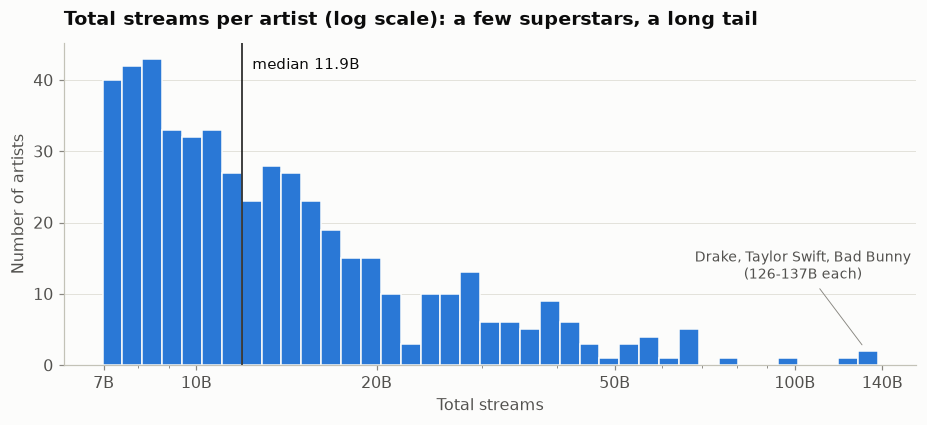

In [19]:
q1, q3 = df['Total Streams'].quantile([0.25, 0.75])
print(f'Artists above the IQR outlier fence ({billions(q3 + 1.5 * (q3 - q1))}):', (df['Total Streams'] > q3 + 1.5 * (q3 - q1)).sum())

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(np.log10(df['Total Streams'].min() / 1000), np.log10(df['Total Streams'].max() / 1000), 40)
ax.hist(df['Total Streams'] / 1000, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.set_xscale('log')
ax.set_xticks([7, 10, 20, 50, 100, 140], labels=['7B', '10B', '20B', '50B', '100B', '140B'])
ax.axvline(df['Total Streams'].median() / 1000, color=INK, linewidth=1)
ax.text(df['Total Streams'].median() / 1000 * 1.04, ax.get_ylim()[1] * 0.92,
        f"median {billions(df['Total Streams'].median())}", color=INK, fontsize=9.5)
top3 = df.nlargest(3, 'Total Streams')
ax.annotate('Drake, Taylor Swift, Bad Bunny\n(126-137B each)', (top3['Total Streams'].mean() / 1000, 2.5), xytext=(-40, 45),
            textcoords='offset points', ha='center', fontsize=9, color=INK_2,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.6))
ax.set(title='Total streams per artist (log scale): a few superstars, a long tail', xlabel='Total streams', ylabel='Number of artists')
ax.grid(axis='x', visible=False)
save(fig, 'q1_total_streams_distribution')
plt.show()

49 artists are "outliers" by the IQR rule, but they are not errors: they are the superstars (Drake, Taylor Swift, Bad Bunny...), the most interesting part of the data.
**Decision:** we keep them, and because of the skew we compare groups with **medians** and use **Spearman** correlations and log scales instead of means and Pearson.

**Non-human "artists".** Disney and League of Legends (soundtrack brands), Bibi Blocksberg (a children's audio-drama character) and Die drei ??? (an audio-drama series)
are not musicians in the usual sense. They are genuinely among the most-streamed "artists" of the platform, so we keep them, but we mention them when they affect a result.

#### 1.7 Summary of the cleaning

In [20]:
df = df.reset_index(drop=True)
df.to_csv(OUT_DIR / 'artist_streams_clean.csv', index=False)
print(f'Clean dataset: {df.shape[0]} artists x {df.shape[1]} columns (saved to outputs/artist_streams_clean.csv)')

Clean dataset: 500 artists x 16 columns (saved to outputs/artist_streams_clean.csv)


| Issue found | Rows | What we did | Why |
|---|---|---|---|
| Exact duplicate rows | 10 | Removed the extra copies | Same record twice would be double-counted |
| Empty record (ID 500) | 1 | Removed | No information at all |
| Missing Total / Solo / Collaborative | 10 | Computed with `Total = Solo + Collab` | Rule holds exactly; checked against the ranking |
| Missing Lead / Feature | 15 | Computed with `Total = Lead + Feature`, floored at 0 | Rule holds within 0.6 % |
| Missing Sex (all groups) | 22 | Labelled `Unknown` | A group has no single sex; dropping would bias group results |
| `Scotland` vs `United Kingdom` | 2 | Merged into `United Kingdom` | Same level of geography for every artist |
| `Sertanjeo` typo, lone `Nu Metal` | 9 + 1 | `Sertanejo`; `Metal` | Spelling; Korn is already `Metal` |
| Years as decimals, date as text | all | `Int64`, `datetime` | Correct types for calculations |
| `Year` constant (2026) | all | Kept, used as reference year | No variation, but needed for career length |
| Lead + Feature slightly ≠ Total | 406 of 480 complete rows | Kept | Gap ≤ 0.6 %, negligible |
| Solo > Lead or Feature > Collab | 33 | Kept, flagged `lead_feature_suspect`; we use Solo/Collab | Impossible by definition; can't know which value is wrong |
| Superstars far above the rest | 49 | Kept; medians, Spearman and log scales | Real values, not errors |

### Q2 · Who is in the data
**a)** *How many unique artists are included? How many pop artists are there?*

In [21]:
n_artists = df['Artist ID'].nunique()
n_pop = (df['Primary Genre'] == 'Pop').sum()
n_kpop = (df['Primary Genre'] == 'K-Pop').sum()
print(f'Unique artists: {n_artists}')
print(f'Pop artists   : {n_pop}   ({n_pop + n_kpop} if the {n_kpop} K-Pop artists are also counted as pop)')

Unique artists: 500
Pop artists   : 102   (113 if the 11 K-Pop artists are also counted as pop)


There are **500 unique artists**, and **102 have Pop as their primary genre**. K-Pop is kept as its own genre in the data,
so the strict answer is 102; with K-Pop included it would be 113.

**b)** *Most common primary genre?* **c)** *Most common country of origin?*

In [22]:
genre_counts = df['Primary Genre'].value_counts()
country_counts = df['Country of Origin'].value_counts()
print(f'Most common genre  : {genre_counts.index[0]} ({genre_counts.iloc[0]} artists, {genre_counts.iloc[0] / n_artists:.0%})')
print(f'Most common country: {country_counts.index[0]} ({country_counts.iloc[0]} artists, {country_counts.iloc[0] / n_artists:.0%})')
pd.DataFrame({'genre': genre_counts.head(5).index, 'artists ': genre_counts.head(5).values,
              'country': country_counts.head(5).index, 'artists': country_counts.head(5).values})

Most common genre  : Hip-Hop (115 artists, 23%)
Most common country: United States (265 artists, 53%)


,genre,artists,country,artists
0,Hip-Hop,115,United States,265
1,Pop,102,United Kingdom,57
2,Rock,60,Mexico,27
3,Reggaeton,43,Canada,18
4,R&B,31,Colombia,16


* **Hip-Hop** is the most common primary genre, with **115 artists** (23 %), just ahead of Pop (102).
* The **United States** is by far the most common country of origin, with **265 artists** (53 %). The UK is a distant second with 57.

**d)** *Top 3 most common primary languages (with a plot).*

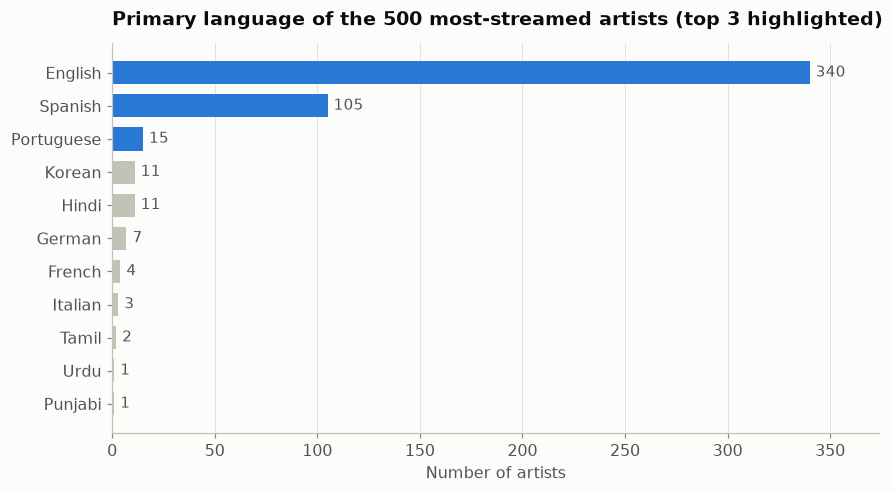

Top 3 languages: {'English': 340, 'Spanish': 105, 'Portuguese': 15}


In [23]:
lang_counts = df['Primary Language'].value_counts().sort_values()
colors = [BLUE if lang in lang_counts.nlargest(3).index else GRAY for lang in lang_counts.index]

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(lang_counts.index, lang_counts.values, color=colors, height=0.7)
ax.bar_label(bars, padding=4, color=INK_2, fontsize=9.5)
ax.set(title='Primary language of the 500 most-streamed artists (top 3 highlighted)', xlabel='Number of artists')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, lang_counts.max() * 1.1)
save(fig, 'q2_languages')
plt.show()
print('Top 3 languages:', lang_counts.nlargest(3).to_dict())

The top 3 languages are **English (340 artists), Spanish (105) and Portuguese (15)**. English alone covers 68 % of the list, and English + Spanish 89 %.
Korean and Hindi follow closely behind Portuguese (11 each).

### Q3 · Update dates
**a)** *How many days ago were the most recent and oldest updates? On what day, month and year did they occur?*

"Days ago" depends on the day the notebook is run, so we compute it from today's date.

In [24]:
TODAY = pd.Timestamp.today().normalize()
latest, oldest = df['Update Date'].max(), df['Update Date'].min()

print(f'Today                : {TODAY:%A, %d %B %Y}')
print(f'Most recent update   : {latest:%A, %d %B %Y}  ->  {(TODAY - latest).days} days ago')
print(f'Oldest update        : {oldest:%A, %d %B %Y}  ->  {(TODAY - oldest).days} days ago')
print(f'Gap between the two  : {(latest - oldest).days} days')

Today                : Saturday, 31 October 2026
Most recent update   : Wednesday, 01 July 2026  ->  122 days ago
Oldest update        : Tuesday, 01 July 2025  ->  487 days ago
Gap between the two  : 365 days


* The **most recent update** was on **Wednesday, 1 July 2026** (day 1, month 7, year 2026).
* The **oldest update** was on **Tuesday, 1 July 2025** (day 1, month 7, year 2025), exactly one year (365 days) earlier.
* The number of days ago is printed above for the day the notebook was run. On 23 October 2026, when we wrote this, they were **114** and **479** days ago.

**b)** *Are there artists whose last update was before the end of 2025? Which ones need an update?*

In [25]:
out_of_date = df[df['Update Date'] < '2026-01-01']
print(f'{len(out_of_date)} artists were last updated before the end of 2025:')
out_of_date[['Artist ID', 'Artist Name', 'Update Date', 'Total Streams']].assign(**{'Total Streams': out_of_date['Total Streams'].map(billions)})

10 artists were last updated before the end of 2025:


,Artist ID,Artist Name,Update Date,Total Streams
109,109,Quavo,2025-07-01,19.4B
175,175,Gucci Mane,2025-07-01,14.9B
193,193,Grupo Frontera,2025-07-01,14.0B
260,260,Elvis Presley,2025-07-01,11.6B
353,353,Teddy Swims,2025-07-01,9.2B
381,381,Alejandro Fernández,2025-07-01,8.6B
387,387,SEVENTEEN,2025-07-01,8.5B
439,439,ScHoolboy Q,2025-07-01,7.8B
478,478,Kane Brown,2025-07-01,7.3B
480,480,Grupo Menos É Mais,2025-07-01,7.3B


**Yes: 10 artists** still have their July 2025 numbers and need an update: Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims,
Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Kane Brown and Grupo Menos É Mais. Their totals are a year behind everyone else's,
so they are *under-estimated*, and their place in the ranking may be too low (an artist who gained many streams in the last year would have moved up).

### Q4 · Career length and collaborations
**a)** *How does the length of an artist's career impact their total streams?*

We measure career length as `Year - Debut Year`, the number of years from the debut to the extraction year (2026).
Because a long career also means more *time* to collect streams, we also look at **streams per career year** (how fast the streams were collected).

In [26]:
df['Career Years'] = df['Year'] - df['Debut Year']
df['Streams per Year'] = df['Total Streams'] / df['Career Years']
career_band = pd.cut(df['Career Years'], [0, 10, 20, 30, 40, 100], right=False,
                     labels=['< 10 years', '10-19', '20-29', '30-39', '40+'])

rho_total, p_total = stats.spearmanr(df['Career Years'], df['Total Streams'])
rho_rate, p_rate = stats.spearmanr(df['Career Years'], df['Streams per Year'])
print(f'Career length vs total streams   : Spearman rho = {rho_total:+.2f} (p = {p_total:.2f})')
print(f'Career length vs streams per year: Spearman rho = {rho_rate:+.2f} (p = {p_rate:.1e})')
# Spearman only detects relationships that keep going one way, so we also compare the career bands directly
kruskal_p = stats.kruskal(*[g['Total Streams'] for _, g in df.groupby(career_band, observed=True)]).pvalue
print(f'Kruskal-Wallis test, total streams across the 5 career bands: p = {kruskal_p:.4f}')
# Robustness 1: count the years of older careers only from 2008 (when Spotify launched), not from before streaming existed
streaming_years = 2026 - df['Debut Year'].clip(lower=2008)
print(f"Streams per year counted from 2008 at the earliest: rho = {stats.spearmanr(df['Career Years'], df['Total Streams'] / streaming_years)[0]:+.2f}")
# Robustness 2: the 10 outdated artists' counts date from 2025, so measure their careers to 2025 instead
career_to_update = (df['Career Years'] - (df['Update Date'].dt.year < 2026)).astype(int)
print(f"Careers measured to each artist's update year: rho = {stats.spearmanr(career_to_update, df['Total Streams'])[0]:+.2f}")
print()
print(df.loc[df['Artist Name'].isin(['Olivia Rodrigo', 'The Beatles']),
             ['Artist ID', 'Artist Name', 'Debut Year', 'Career Years', 'Total Streams']].to_string(index=False))

(df.groupby(career_band, observed=True)
   .agg(artists=('Artist ID', 'size'), median_total=('Total Streams', 'median'), median_per_year=('Streams per Year', 'median'))
   .assign(median_total=lambda t: t['median_total'].map(billions), median_per_year=lambda t: t['median_per_year'].map(billions)))

Career length vs total streams   : Spearman rho = -0.01 (p = 0.78)
Career length vs streams per year: Spearman rho = -0.72 (p = 3.8e-80)
Kruskal-Wallis test, total streams across the 5 career bands: p = 0.0006
Streams per year counted from 2008 at the earliest: rho = -0.50
Careers measured to each artist's update year: rho = -0.01

 Artist ID    Artist Name  Debut Year  Career Years  Total Streams
        61 Olivia Rodrigo        2021             5        28799.7
        72    The Beatles        1962            64        26130.5


,artists,median_total,median_per_year
Career Years,,,
< 10 years,67,10.3B,1.5B
10-19,241,13.3B,0.9B
20-29,105,11.5B,0.5B
30-39,37,11.1B,0.4B
40+,50,9.6B,0.2B


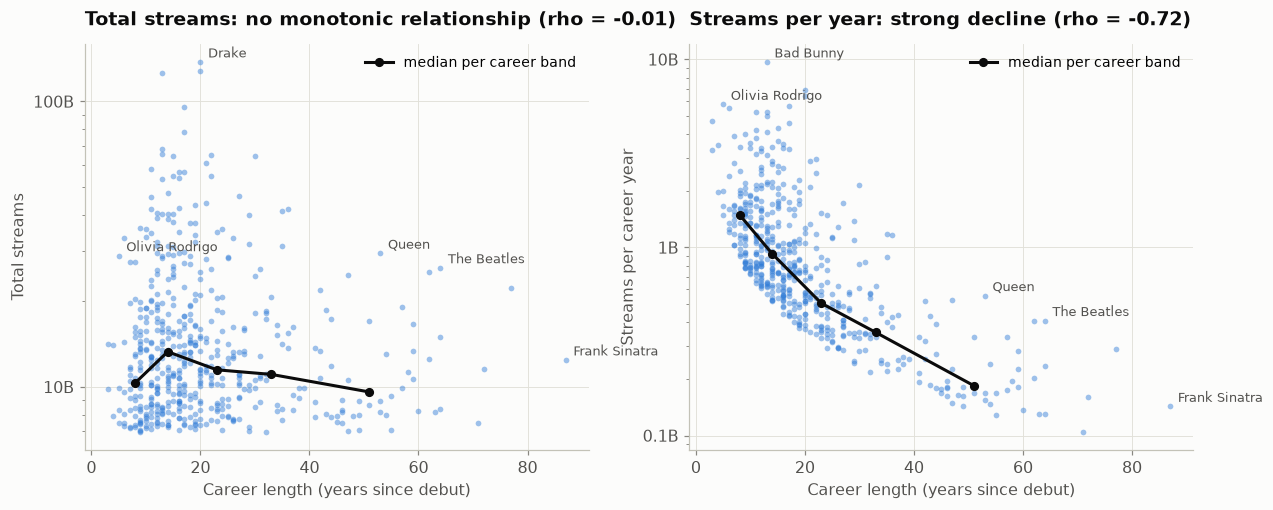

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
panels = [('Total Streams', 'Total streams', f'Total streams: no monotonic relationship (rho = {rho_total:+.2f})',
           ['Drake', 'Olivia Rodrigo', 'Queen', 'The Beatles', 'Frank Sinatra']),
          ('Streams per Year', 'Streams per career year', f'Streams per year: strong decline (rho = {rho_rate:+.2f})',
           ['Bad Bunny', 'Olivia Rodrigo', 'Queen', 'The Beatles', 'Frank Sinatra'])]
for ax, (col, label, title, highlight) in zip(axes, panels):
    ax.scatter(df['Career Years'], df[col] / 1000, s=14, color=BLUE, alpha=0.45, linewidths=0)
    trend = df.groupby(career_band, observed=True).agg(x=('Career Years', 'median'), y=(col, 'median'))
    ax.plot(trend['x'], trend['y'] / 1000, color=INK, linewidth=2, marker='o', markersize=5, label='median per career band')
    for _, r in df[df['Artist Name'].isin(highlight)].iterrows():
        ax.annotate(r['Artist Name'], (r['Career Years'], r[col] / 1000), xytext=(5, 3), textcoords='offset points', fontsize=8.5, color=INK_2)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}B'))
    ax.set(title=title, xlabel='Career length (years since debut)', ylabel=label)
    ax.legend(loc='upper right', fontsize=9)
save(fig, 'q4a_career_length')
plt.show()

**What we conclude:**
* **There is no monotonic association between career length and total streams** (Spearman ρ ≈ -0.01, p = 0.78): a 5-year-old career (Olivia Rodrigo, 28.8 B)
  is ranked only 11 places above a 64-year-old one (The Beatles, 26.1 B). Totals do differ somewhat between career bands (Kruskal-Wallis p < 0.001), rising to a peak
  for 10-19 years and then falling. Because the list only contains artists above about 7 B streams, this cannot tell us whether longer careers *produce* more streams.
* The highest median belongs to careers of **10-19 years**, i.e. artists who debuted in 2007-2016, at the same time as music streaming took off.
  A plausible reading: they grew up *with* the platforms.
* **Streams per career year fall sharply with career length** (ρ = -0.72). Part of this is arithmetic: we divide by career length, and every artist here has about 7 B streams or more,
  so a long career *must* mean a lower yearly rate. It also counts years before streaming existed (64 for The Beatles); counting older careers only from 2008, when Spotify launched, the decline is weaker
  (ρ = -0.50) but still clear. The informative part is the comparison with the first chart: since totals do not grow with time, recent artists reach the list *much faster*
  (median 1.5 B/year for careers under 10 years vs 0.2 B/year for 40+). Older artists collected their streams slowly from their back catalogue,
  and the ones still in the top 500 are the few whose songs remain popular (The Beatles, Queen).

So, inside the top 500, a long career is no guarantee of more streams: what counts is the size of the audience in the streaming era.

*(Caveat: `Year` is 2026 for everyone, including the 10 artists whose streams date from 2025. Measuring their careers to 2025 instead does not change the result, see the robustness line printed above.)*

**b)** *Top 5 artists that benefit the most from collaborations (largest % of streams from collaborations).*

We use the **Solo/Collaborative** split (consistent for every artist, see 1.6): `Collab Share = Collaborative Streams / Total Streams`.

In [28]:
df['Collab Share'] = df['Collaborative Streams'] / df['Total Streams'] * 100

# Several artists are tied at 100 %, so ties are broken by the absolute number of collaborative streams
collab_rank = df.sort_values(['Collab Share', 'Collaborative Streams'], ascending=False)
print('Artists with 100 % of their streams from collaborations:', (df['Collab Share'] == 100).sum())
tied = df[df['Collab Share'] == 100]
feature_share = (tied['Feature Streams'] / tied['Total Streams'] * 100).sort_values(ascending=False, kind='stable')
print('Alternative tie-break (share of featured streams):', ', '.join(f"{tied.at[i, 'Artist Name']} ({v:.2f}%)" for i, v in feature_share.head(5).items()))
collab_rank[['Artist Name', 'Primary Genre', 'Collab Share', 'Collaborative Streams', 'Solo Streams']].head(10).round(2)

Artists with 100 % of their streams from collaborations: 7
Alternative tie-break (share of featured streams): Magenta (100.00%), Ryan Lewis (100.00%), Amitabh Bhattacharya (99.99%), Kumaar (98.82%), Disney (98.79%)


,Artist Name,Primary Genre,Collab Share,Collaborative Streams,Solo Streams
89,Disney,Soundtrack,100.00,22236.1,0.0
246,Amitabh Bhattacharya,Filmi,100.00,12136.7,0.0
277,Irshad Kamil,Filmi,100.00,11014.9,0.0
372,DJ Luian,Reggaeton,100.00,8801.6,0.0
447,Kumaar,Pop,100.00,7689.5,0.0
483,Magenta,Pop,100.00,7239.7,0.0
484,Ryan Lewis,Hip-Hop,100.00,7237.6,0.0
392,Mambo Kingz,Reggaeton,99.98,8456.1,1.3
63,Pritam,Pop,99.96,28532.2,11.7
489,benny blanco,Pop,99.95,7110.2,3.9


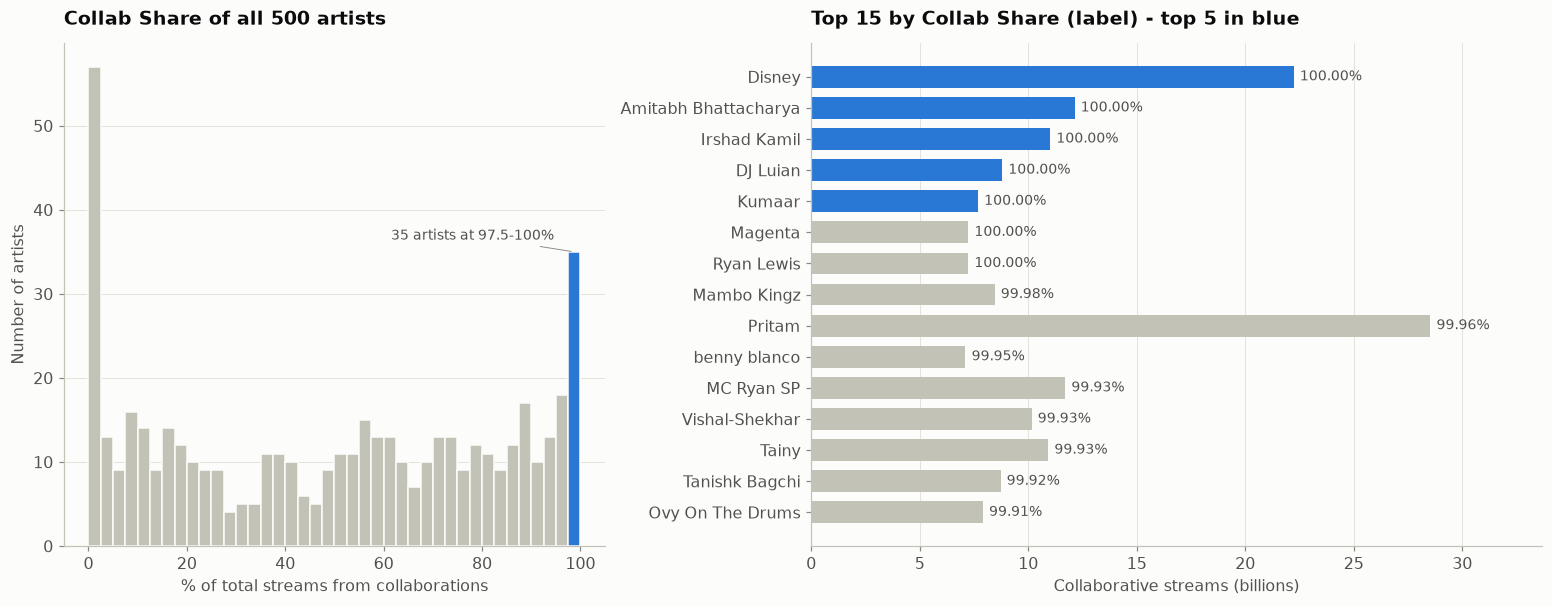

In [29]:
top15 = collab_rank.head(15).iloc[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.35]}, layout='constrained')

# Left: how unusual a 100 % collaborative career is
ax1.hist(df['Collab Share'], bins=np.arange(0, 102.5, 2.5), color=GRAY, edgecolor=SURFACE, linewidth=1)
ax1.hist(df.loc[df['Collab Share'] >= 97.5, 'Collab Share'], bins=[97.5, 100.01], color=BLUE, edgecolor=SURFACE)
ax1.annotate(f"{(df['Collab Share'] >= 97.5).sum()} artists at 97.5-100%", (98.75, (df['Collab Share'] >= 97.5).sum()),
             xytext=(-120, 8), textcoords='offset points', fontsize=9, color=INK_2,
             arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.6))
ax1.set(title='Collab Share of all 500 artists', xlabel='% of total streams from collaborations', ylabel='Number of artists')
ax1.grid(axis='x', visible=False)

# Right: the 15 highest Collab Shares, with the tie-breaker (collaborative streams)
colors = [GRAY] * 10 + [BLUE] * 5
bars = ax2.barh(top15['Artist Name'], top15['Collaborative Streams'] / 1000, color=colors, height=0.7)
ax2.bar_label(bars, labels=[f"{v:.2f}%" for v in top15['Collab Share']], padding=4, fontsize=9, color=INK_2)
ax2.set_xlim(0, top15['Collaborative Streams'].max() / 1000 * 1.18)
ax2.set(title='Top 15 by Collab Share (label) - top 5 in blue', xlabel='Collaborative streams (billions)')
ax2.grid(axis='y', visible=False)
save(fig, 'q4b_collaborations')
plt.show()

**Seven artists get 100 % of their streams from collaborations**, so a rule is needed to pick 5. We rank the ties by the *amount* of collaborative streams
(the artists who gain the most in absolute terms). The **top 5** are:

1. **Disney** (22.2 B collaborative streams)
2. **Amitabh Bhattacharya** (12.1 B)
3. **Irshad Kamil** (11.0 B)
4. **DJ Luian** (8.8 B)
5. **Kumaar** (7.7 B)

(Magenta and Ryan Lewis are also at 100 %, with less volume.)

**The tie-break is a choice, and we say so.** Another reasonable rule, e.g. ranking the ties by the share of *featured* streams, would give a different top 5 (Magenta and Ryan Lewis tied at 100 %, then Amitabh Bhattacharya, Kumaar and Disney; printed above). What does not depend on the rule is the list of seven artists at 100 %. Note also that Disney, first on our list, is a brand rather than a person (see 1.6), so the top *individual* artists are Amitabh Bhattacharya, Irshad Kamil, DJ Luian, Kumaar and Magenta.

**Interpretation.** These are not singers who occasionally collaborate: their *role* is collaborative by nature.
Amitabh Bhattacharya, Irshad Kamil and Kumaar are **Bollywood lyricists**, credited next to the singers of film songs; DJ Luian is a **reggaeton producer/DJ**;
Disney's tracks are typically credited together with the film's performers; Ryan Lewis is the producer half of Macklemore & Ryan Lewis.
Just below 100 % we find more producers (Mambo Kingz, Tainy, Ovy On The Drums, benny blanco) and the composer Pritam.
For these artists collaborations are not a bonus, they are the whole career: without them they would not be in the ranking at all.

### Q5 · Additional insights
We looked at how genre, artist type, sex, language and debut period relate to streams and collaborations. Three main insights and two shorter extras:

#### Insight 1 · Collaboration depends on the genre, but collaborating more does not go with more streams

In [30]:
GENRE_FAMILY = {'Hip-Hop': 'Hip-Hop & R&B', 'R&B': 'Hip-Hop & R&B', 'Pop': 'Pop', 'K-Pop': 'Pop',
                'Reggaeton': 'Latin', 'Latin': 'Latin', 'Regional Mexican': 'Latin', 'Bachata': 'Latin',
                'Rock': 'Rock & Metal', 'Metal': 'Rock & Metal', 'Alternative': 'Rock & Metal'}
df['Genre Family'] = df['Primary Genre'].map(GENRE_FAMILY).fillna('Other genres')

rows = []
for family, g in df.groupby('Genre Family'):
    rho, p = stats.spearmanr(g['Collab Share'], g['Total Streams'])
    low, high = np.tanh(np.arctanh(rho) + np.array([-1.96, 1.96]) / np.sqrt(len(g) - 3))   # 95 % interval (Fisher z)
    rows.append({'Genre Family': family, 'artists': len(g), 'median Collab Share %': g['Collab Share'].median(),
                 'rho (Collab Share vs Total)': rho, '95% interval': f'{low:+.2f} to {high:+.2f}', 'p-value': p})
family_tbl = pd.DataFrame(rows).sort_values('median Collab Share %').round(2)
rho_all, p_all = stats.spearmanr(df['Collab Share'], df['Total Streams'])
print(f'All artists: rho (Collab Share vs Total Streams) = {rho_all:+.2f}, p = {p_all:.2f}')
family_tbl

All artists: rho (Collab Share vs Total Streams) = +0.06, p = 0.16


,Genre Family,artists,median Collab Share %,rho (Collab Share vs Total),95% interval,p-value
4,Rock & Metal,78,1.82,-0.04,-0.26 to +0.19,0.73
3,Pop,113,34.87,0.01,-0.18 to +0.19,0.92
0,Hip-Hop & R&B,146,65.36,-0.08,-0.24 to +0.08,0.33
1,Latin,95,74.18,0.02,-0.18 to +0.22,0.82
2,Other genres,68,76.69,0.15,-0.10 to +0.37,0.23


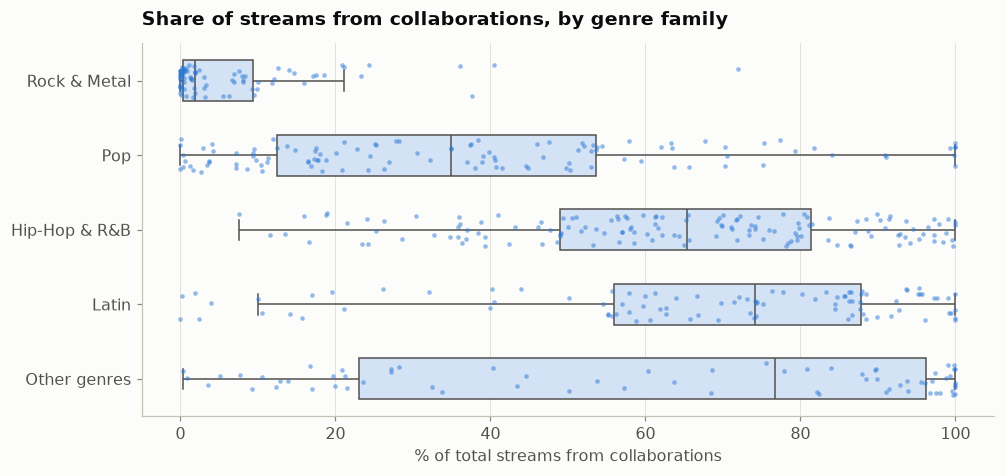

In [31]:
order = family_tbl['Genre Family'].tolist()
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.boxplot(data=df, y='Genre Family', x='Collab Share', order=order, color='#cde2fb', width=0.55,
            fliersize=0, linewidth=1, linecolor=INK_2, ax=ax)
sns.stripplot(data=df, y='Genre Family', x='Collab Share', order=order, color=BLUE, size=3, alpha=0.5, jitter=0.22, ax=ax)
ax.set(title='Share of streams from collaborations, by genre family', xlabel='% of total streams from collaborations', ylabel='')
ax.grid(axis='y', visible=False)
save(fig, 'q5_collab_by_genre')
plt.show()

* Collaboration is a **genre habit**: the median Rock & Metal artist gets **under 2 %** of streams from collaborations, the median Latin artist **74 %**.
  Hip-Hop & R&B (65 %) and the "other" family (EDM DJs, Bollywood composers, 77 %) are also collaboration-driven.
* But **inside each genre, we find no link between collaborating more and having more streams**: every within-family correlation is close to 0 and none is significant
  (overall ρ = +0.06, p = 0.16). The 95 % intervals (from about -0.26 to +0.37) still allow a small effect, so the data give no support to "more features, more streams",
  but cannot rule out a modest one.

#### Insight 2 · Groups are rare at the very top, and they barely collaborate

In [32]:
def share_in_top(mask, data, ks=(10, 50, 100)):
    """% of the rows of `data` matching `mask` among its top-k by total streams, and among all of them."""
    ranked = mask.loc[data.sort_values('Total Streams', ascending=False).index]
    return pd.Series({f'top {k}': ranked.head(k).mean() * 100 for k in ks} | {f'all {len(data)}': mask.mean() * 100})

# A band's "Sex" label (e.g. 'Male' for an all-male band) is not comparable with a person's,
# so the comparison of women and men uses solo artists only
solo_artists = df[df['Artist Type'] == 'Solo']
is_group, is_female = df['Artist Type'] == 'Group', solo_artists['Sex'] == 'Female'
type_tbl = df.groupby('Artist Type').agg(artists=('Artist ID', 'size'), median_total=('Total Streams', 'median'),
                                         median_collab_share=('Collab Share', 'median')).round(1)
u_type = stats.mannwhitneyu(df.loc[~is_group, 'Total Streams'], df.loc[is_group, 'Total Streams'])
print(f'Solo vs group total streams, Mann-Whitney U test: p = {u_type.pvalue:.4f}')
by_streams = df.sort_values('Total Streams', ascending=False).reset_index(drop=True)
first_group = by_streams[by_streams['Artist Type'] == 'Group'].iloc[0]
print(f"Biggest group: {first_group['Artist Name']}, rank {first_group.name + 1} of 500")
# If groups were spread at random over the ranking, how likely would it be to see this few of them at the top? (hypergeometric distribution)
for k in (10, 50):
    observed = by_streams.head(k)['Artist Type'].eq('Group').sum()
    p_chance = stats.hypergeom.cdf(observed, len(df), is_group.sum(), k)
    print(f'Groups in the top {k}: {observed} (expected {k * is_group.mean():.1f} at random); probability of {observed} or fewer by chance: {p_chance:.3f}')
display(type_tbl)
display(share_in_top(is_group, df).round(1).to_frame('% groups (all artists)').T)
share_in_top(is_female, solo_artists).round(1).to_frame('% women (solo artists)').T

Solo vs group total streams, Mann-Whitney U test: p = 0.0015
Biggest group: BTS, rank 18 of 500
Groups in the top 10: 0 (expected 2.5 at random); probability of 0 or fewer by chance: 0.052
Groups in the top 50: 5 (expected 12.7 at random); probability of 5 or fewer by chance: 0.004


,artists,median_total,median_collab_share
Artist Type,,,
Group,127,10607.0,8.0
Solo,373,12700.7,61.3


,top 10,top 50,top 100,all 500
% groups (all artists),0.0,10.0,17.0,25.4


,top 10,top 50,top 100,all 373
% women (solo artists),20.0,28.0,24.0,22.0


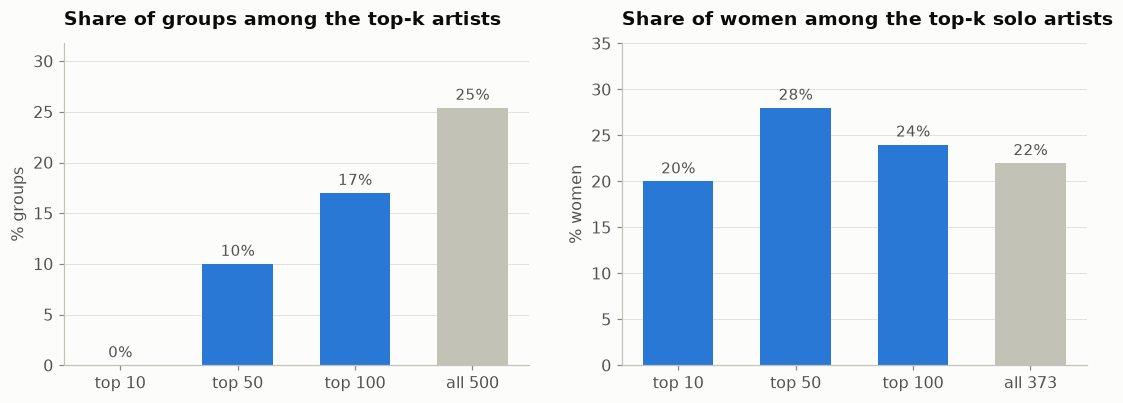

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
panels = [('groups', 'artists', is_group, df), ('women', 'solo artists', is_female, solo_artists)]
for ax, (label, among, mask, data) in zip(axes, panels):
    s = share_in_top(mask, data)
    bars = ax.bar(s.index, s.values, color=[BLUE] * 3 + [GRAY], width=0.6)
    ax.bar_label(bars, labels=[f'{v:.0f}%' for v in s.values], padding=3, color=INK_2, fontsize=9.5)
    ax.set(title=f'Share of {label} among the top-k {among}', ylabel=f'% {label}')
    ax.set_ylim(0, max(30, s.max() * 1.25))
    ax.grid(axis='x', visible=False)
save(fig, 'q5_groups_women_top')
plt.show()

* Groups are **25 % of the list but 0 % of the top 10 and 10 % of the top 50**, and their median total is lower (10.6 B vs 12.7 B, Mann-Whitney p = 0.002).
  With 2.5 groups expected in a random top 10, zero could still be luck (probability 0.05); the top 50 is the stronger evidence (5 instead of 12.7, probability 0.004).
  The biggest group, BTS, is only 18th.
* Groups get a median of just **8 %** of their streams from collaborations, against **61 %** for solo artists. A band already *is* a collaboration,
  and it rarely features on other artists' songs. Solo artists use features to reach new audiences, which may be one reason they dominate the top.

**Extra · Women are under-represented in the list, but not once they are in it.** (Solo artists only: a band's sex label is not comparable with a person's.)
Only 22 % of the solo artists are women, and they make up 20-28 % of the top 10, 50 and 100 solo artists (about the same share, so no drop at the top); (Taylor Swift is #2 overall),
and we find no significant difference between women's and men's totals (which does not prove they are equal):

In [34]:
u_sex = stats.mannwhitneyu(solo_artists.loc[solo_artists['Sex'] == 'Female', 'Total Streams'],
                           solo_artists.loc[solo_artists['Sex'] == 'Male', 'Total Streams'])
sex_counts = solo_artists['Sex'].value_counts()
print(f"Solo artists: {sex_counts['Male']} men, {sex_counts['Female']} women ({sex_counts['Male'] / sex_counts['Female']:.1f} men per woman)")
print(solo_artists.groupby('Sex')['Total Streams'].median().map(billions).to_string())
print(f'Mann-Whitney U test, women vs men (solo artists): p = {u_sex.pvalue:.2f}')

Solo artists: 291 men, 82 women (3.5 men per woman)
Sex
Female    12.3B
Male      12.8B
Mann-Whitney U test, women vs men (solo artists): p = 0.77


So the imbalance is in **how many** women are in the list (about 3.5 solo men for every solo woman), not in how much they stream once there.
Without data on artists outside the list, we cannot say whether this reflects a barrier to entry.

#### Insight 3 · The newest entrants are mostly non-English

In [35]:
decade = pd.cut(df['Debut Year'], [0, 1970, 1980, 1990, 2000, 2010, 2020, 2030], right=False,
                labels=['before 1970', '1970s', '1980s', '1990s', '2000s', '2010s', '2020s'])
by_decade = (df.assign(non_english=df['Primary Language'] != 'English')
               .groupby(decade, observed=True)
               .agg(artists=('Artist ID', 'size'), pct_non_english=('non_english', 'mean'),
                    share_of_streams=('Total Streams', 'sum')))
by_decade['pct_non_english'] *= 100
by_decade['share_of_streams'] = by_decade['share_of_streams'] / df['Total Streams'].sum() * 100
display(by_decade.round(1))
print('Languages of the 2020s debuts:', df.loc[df['Debut Year'] >= 2020, 'Primary Language'].value_counts().to_dict())
# Is the 2020s share different from the 2010s by more than chance? (Fisher's exact test on a 2x2 table)
non_english, debut_2020s, debut_2010s = df['Primary Language'] != 'English', df['Debut Year'] >= 2020, df['Debut Year'].between(2010, 2019)
table = [[(debut_2020s & non_english).sum(), (debut_2020s & ~non_english).sum()],
         [(debut_2010s & non_english).sum(), (debut_2010s & ~non_english).sum()]]
print(f"Fisher's exact test, 2020s vs 2010s debuts: p = {stats.fisher_exact(table).pvalue:.4f}")
print(f"Median Collab Share: 2020s debuts {df.loc[debut_2020s, 'Collab Share'].median():.0f}% vs everyone else {df.loc[~debut_2020s, 'Collab Share'].median():.0f}%")
df.loc[debut_2020s, ['Artist Name', 'Debut Year', 'Primary Language', 'Primary Genre', 'Country of Origin']].sort_values('Debut Year')

,artists,pct_non_english,share_of_streams
Debut Year,,,
before 1970,17,5.9,2.8
1970s,16,31.2,2.2
1980s,23,47.8,3.0
1990s,52,28.8,10.2
2000s,146,24.0,32.3
2010s,232,35.3,47.4
2020s,14,78.6,2.1


Languages of the 2020s debuts: {'Spanish': 8, 'English': 3, 'Korean': 2, 'Portuguese': 1}
Fisher's exact test, 2020s vs 2010s debuts: p = 0.0028
Median Collab Share: 2020s debuts 62% vs everyone else 52%


,Artist Name,Debut Year,Primary Language,Primary Genre,Country of Origin
46,Peso Pluma,2020,Spanish,Regional Mexican,Mexico
185,Quevedo,2020,Spanish,Reggaeton,Spain
337,Oscar Maydon,2020,Spanish,Latin,Mexico
420,Eslabon Armado,2020,Spanish,Regional Mexican,United States
461,ENHYPEN,2020,Korean,K-Pop,South Korea
479,Laufey,2020,English,Pop,Iceland
322,Benson Boone,2021,English,Pop,United States
61,Olivia Rodrigo,2021,English,Pop,United States
463,Ana Castela,2021,Portuguese,Sertanejo,Brazil
404,Milo j,2021,Spanish,Hip-Hop,Argentina


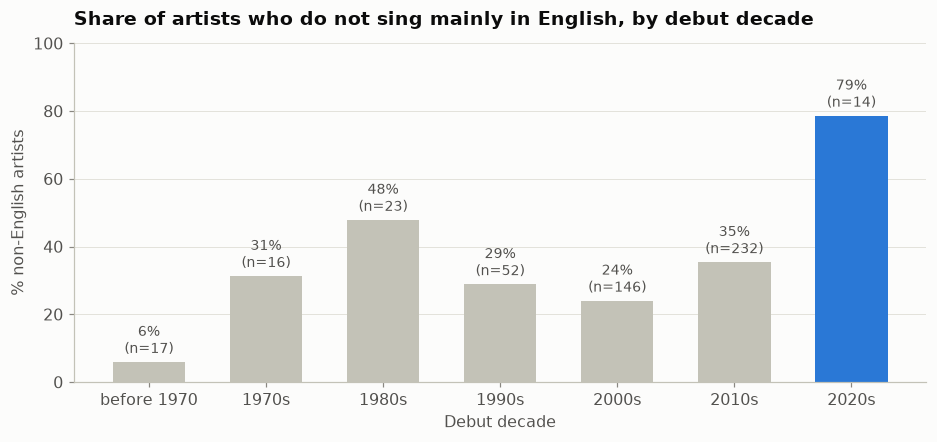

In [36]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(by_decade.index.astype(str), by_decade['pct_non_english'], color=[GRAY] * 6 + [BLUE], width=0.62)
ax.bar_label(bars, labels=[f"{p:.0f}%\n(n={n})" for p, n in zip(by_decade['pct_non_english'], by_decade['artists'])],
             padding=3, color=INK_2, fontsize=9)
ax.set_ylim(0, 100)
ax.set(title='Share of artists who do not sing mainly in English, by debut decade', xlabel='Debut decade', ylabel='% non-English artists')
ax.grid(axis='x', visible=False)
save(fig, 'q5_language_by_decade')
plt.show()

* Among artists who debuted in the **2020s, 79 % do not sing mainly in English**, against 24-35 % for the 2000s and 2010s. Spanish dominates (8 of the 14),
  and 6 of those 8 make Mexican music (regional Mexican or Latin acts from Mexico and the US: Peso Pluma, Tito Double P, Grupo Frontera...).
* The 2020s group is small (14 artists), because new artists have had less time to collect streams. The difference with the 2010s is unlikely to be chance
  (Fisher's exact test p = 0.003), but this is one snapshot of a cumulative list, not a trend measured over time, and earlier decades show no steady pattern
  (48 % for the 1980s, 24 % for the 2000s). Two readings fit: streaming has made Latin and other non-English markets big enough to produce top artists quickly;
  and reaching an all-time list within six years is easier in collaboration-heavy scenes, where a joint song counts for every artist on it (median collaboration
  share of the 2020s debuts: 62 %, against 52 % for everyone else).
* The 2000s and 2010s debuts together account for **80 % of all streams**, so the list is dominated by the generation that grew up with streaming (consistent with Q4a).

#### Extra · Streams are concentrated, even among the top 500

Gini coefficient: 0.36 | top 10 artists (2% of the list) hold 10.6% of all streams
US artists: 53% of the list and 57% of the streams
Drake has 11.5 times the streams of the median artist


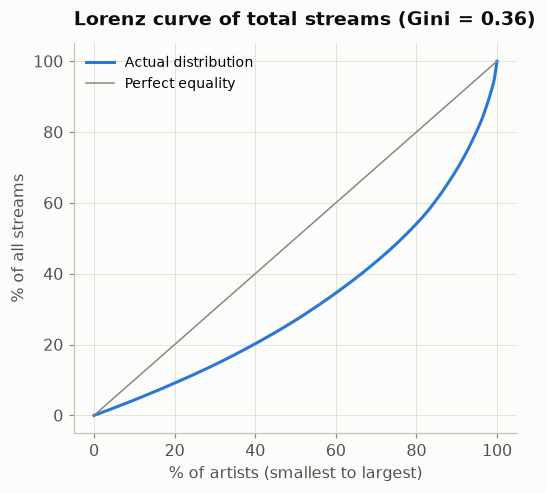

In [37]:
sorted_streams = np.sort(df['Total Streams'].to_numpy())
cum_share = np.insert(sorted_streams.cumsum() / sorted_streams.sum(), 0, 0)
n = len(sorted_streams)
gini = (2 * np.arange(1, n + 1) - n - 1) @ sorted_streams / (n * sorted_streams.sum())
top10_share = df.nlargest(10, 'Total Streams')['Total Streams'].sum() / df['Total Streams'].sum() * 100
us_share = df.loc[df['Country of Origin'] == 'United States', 'Total Streams'].sum() / df['Total Streams'].sum() * 100
print(f'Gini coefficient: {gini:.2f} | top 10 artists (2% of the list) hold {top10_share:.1f}% of all streams')
print(f'US artists: {country_counts["United States"] / n_artists:.0%} of the list and {us_share:.0f}% of the streams')
print(f"Drake has {df['Total Streams'].max() / df['Total Streams'].median():.1f} times the streams of the median artist")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot(np.linspace(0, 100, n + 1), cum_share * 100, color=BLUE, linewidth=2, label='Actual distribution')
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1, label='Perfect equality')
ax.set(title=f'Lorenz curve of total streams (Gini = {gini:.2f})', xlabel='% of artists (smallest to largest)', ylabel='% of all streams')
ax.legend(loc='upper left', fontsize=9)
save(fig, 'q5_lorenz')
plt.show()

Even inside an elite list, the **top 10 artists (2 %) hold 10.6 % of all streams** and Drake alone has 11.5 times the median artist (Gini 0.36).
US artists make up 53 % of the list and **57 % of the streams**.

## 2. Advanced Topic: Interactive Maps

Goal: interactive world maps to explore where the most-streamed artists come from, with their genre, language and streams.
This needs the **birthplace or origin** of each artist, and the **coordinates** of that place, collected from Wikipedia by web scraping.

### 2.1 Web scraping Wikipedia

**How our scraper works** (one artist at a time):

```
Wikipedia Main Page ──(its search box)──► artist's article ──(infobox: "Born" or "Origin")──► place's article ──(its coordinates)──► latitude, longitude
```

1. **Start at the Main Page** and read its search form (where it sends the query and the name of the text field). Every search goes through that form, exactly as if we typed the name into the search box.
2. **Find the artist's article.** If the exact name leads straight to a music article, we take it. If not (e.g. "Drake" is a page listing many Drakes, "Future" is about time), we look at the **disambiguation page** or the **search results**.
   A candidate is accepted only if it is a *music* article whose title matches the name, and among several candidates we prefer the one whose birthplace is in the artist's **Country of Origin** and that mentions their **genre**.
   These are rules of thumb, not guarantees: two musicians with the same name and country, or an artist born abroad, can still fool them. That is why every match is checked afterwards (section 2.2).
3. **Read the place** from the infobox (the summary box at the top right): the birthplace in "Born" for solo artists, the "Origin" for groups. Articles without such a box are read for phrases like *"born in"* or *"a band from"*.
4. **Open the place's article** (we follow the link, most precise first: hospital → city → state) and read the **coordinates** at the top of the page. If the place has no link, we search its name through the same search box.

Every location and every coordinate comes from Wikipedia pages reached this way, as the brief requires. We send a descriptive User-Agent, pause between requests, retry when Wikipedia asks us to slow down,
and download each place only once (many artists share a city).

The code is in the next cells, one step per cell.

**Downloading pages.** `get_soup` downloads a page and turns the HTML into a BeautifulSoup object we can search. It handles the errors we met while building this: network errors and *HTTP 429 (too many requests)*, when we wait and try again.

In [38]:
# --- Downloading pages ---
BASE = 'https://en.wikipedia.org'
MAIN_PAGE = BASE + '/wiki/Main_Page'

# Wikipedia asks automated clients to identify themselves with a descriptive User-Agent
session = requests.Session()
session.headers.update({'User-Agent': 'NOVA-IMS-PDS-student-project/1.0 (educational project; https://www.novaims.unl.pt)'})
failed_requests = []                                   # (url, reason) of every request that did not succeed


def get_soup(url, params=None, pause=0.2, retries=5):
    """Download a page and return (BeautifulSoup, final_url), or (None, url) if it keeps failing.
    Waits and retries when Wikipedia says we are going too fast (HTTP 429/503) or the network fails."""
    for attempt in range(1, retries + 1):
        try:
            r = session.get(url, params=params, timeout=20)
        except requests.RequestException as error:
            failed_requests.append((url, type(error).__name__))
            time.sleep(2 * attempt)
            continue
        if r.status_code == 200:
            time.sleep(pause)                          # be polite: a short pause between requests
            return BeautifulSoup(r.text, 'html.parser'), r.url
        failed_requests.append((url, r.status_code))
        if r.status_code not in (429, 503):            # e.g. 404: retrying will not help
            return None, r.url
        wait = r.headers.get('Retry-After', '')
        time.sleep(int(wait) if wait.isdigit() else 5 * attempt)
    return None, url

**Step 1 · The Main Page's search box.** We read the search form of the Main Page. `search_wikipedia` then submits any query through it.

In [39]:
# --- Step 1 - start from the Main Page and use its search box ---
main_soup, _ = get_soup(MAIN_PAGE)
ONLINE = main_soup is not None and main_soup.find('form', id='searchform') is not None
if ONLINE:
    search_form = main_soup.find('form', id='searchform')                        # the search box at the top
    SEARCH_URL = urljoin(BASE, search_form['action'])                           # where the form sends the query
    SEARCH_FIELD = search_form.find('input', {'type': 'search'})['name']         # name of the text field
    HIDDEN_FIELDS = {i['name']: i.get('value', '') for i in search_form.find_all('input', type='hidden')}
else:                                                    # no internet (or the page changed): the notebook uses saved results
    SEARCH_URL, SEARCH_FIELD, HIDDEN_FIELDS = BASE + '/w/index.php', 'search', {'title': 'Special:Search'}


def search_wikipedia(query, fulltext=False):
    """Submit `query` through the Main Page search form. Like pressing Enter in the search box, Wikipedia
    jumps straight to the article with that exact title (if any). With fulltext=True we get the list of results."""
    params = {SEARCH_FIELD: query, **HIDDEN_FIELDS}
    if fulltext:
        params['fulltext'] = '1'
    return get_soup(SEARCH_URL, params)


def result_links(soup, n=8):
    """Article URLs listed on a page of search results."""
    return [urljoin(BASE, a['href']) for a in soup.select('.mw-search-result-heading a')[:n]]

In [40]:
print('Connected to Wikipedia:', ONLINE)
print('Main Page search form ->', SEARCH_URL, '| text field:', SEARCH_FIELD, '| hidden fields:', HIDDEN_FIELDS)

Connected to Wikipedia: True
Main Page search form -> https://en.wikipedia.org/w/index.php | text field: search | hidden fields: {'title': 'Special:Search'}


**Reading an article.** Helpers to read the infobox (the summary box at the top right of an article), and to recognise disambiguation pages and music articles.

In [41]:
# --- Reading an article ---
def page_title(soup):
    heading = soup.select_one('#firstHeading')
    return heading.get_text(' ', strip=True) if heading else ''


def infobox_rows(soup):
    """{label: <td> cell} for every labelled row of the article's infobox (the summary box on the right)."""
    rows = {}
    box = soup.select_one('table.infobox')
    if box is not None:
        for tr in box.select('tr'):
            th, td = tr.find('th', class_='infobox-label'), tr.find('td', class_='infobox-data')
            if th and td:
                rows.setdefault(th.get_text(' ', strip=True), td)
    return rows


def is_disambiguation(soup):
    """Disambiguation pages list the different meanings of a name ('Drake' -> rapper, surname, bird...)."""
    if soup.select_one('#disambigbox, .dmbox-disambig, #setindexbox') is not None:
        return True
    return any('Disambiguation pages' in a.get_text() for a in soup.select('#catlinks a'))


MUSIC_WORDS = re.compile(r'\b(singers?|rappers?|musicians?|bands?|banda|songwriters?|composers?|lyricists?|'
                         r'djs?|disc jockey|record producers?|producers?|duo|groups?|vocalists?|guitarists?|music)\b')


def is_music_page(soup):
    """Is this article about a musical act (singer, band, DJ, composer...)?"""
    rows = infobox_rows(soup)
    if any(k in rows for k in ('Released', 'Recorded', 'Network', 'Original release')):
        return False                                   # an album, a song or a TV show, not an artist
    if any(k in rows for k in ('Genres', 'Labels', 'Instruments', 'Instrument', 'Instrument(s)', 'Members', 'Past members')):
        return True
    box = soup.select_one('table.infobox')
    if box is None:                                    # no infobox: read the first paragraph instead
        lead = soup.select_one('#mw-content-text p:not(.mw-empty-elt)')
        return lead is not None and MUSIC_WORDS.search(lead.get_text().lower()) is not None
    if 'Background information' in box.get_text():
        return True
    occupation = ' '.join(td.get_text(' ') for label, td in rows.items() if label.startswith('Occupation'))
    return MUSIC_WORDS.search(occupation.lower()) is not None

**Comparing names.** The dataset and Wikipedia often write the same name differently (`'JAŸ-Z'` vs `'Jay-Z'`, `'P!nk'` vs `'Pink (singer)'`, `'Måneskin'`),
so we compare simplified versions: lower case, no accents, no punctuation, no "(singer)"-style qualifiers.
`difflib.SequenceMatcher` gives a similarity between 0 and 1 for names that are still slightly different.

In [42]:
# --- Comparing names written differently ---
def normalize(text):
    """Lower-case and remove accents, punctuation and '(...)' qualifiers: 'Måneskin' -> 'maneskin'."""
    for a, b in {'ø': 'o', 'Ø': 'O', 'æ': 'ae', 'ß': 'ss', '&': ' and ', '$': 's', '!': 'i'}.items():
        text = text.replace(a, b)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    text = re.sub(r'\(.*?\)', ' ', text.lower())
    return ' '.join(re.sub(r'[^a-z0-9 ]', ' ', text).split())


def name_matches(artist, title):
    """Can this Wikipedia title refer to this artist? ('Queen (band)' -> 'Queen': yes)"""
    a, t = normalize(artist), normalize(title)
    if not a or not t:
        return False
    if a == t:
        return True
    a_words, t_words = set(a.split()), set(t.split())
    # 'Banda MS' vs 'Banda MS de Sergio Lizárraga': one name inside the other (at least 2 words)
    if min(len(a_words), len(t_words)) >= 2 and (a_words <= t_words or t_words <= a_words):
        return True
    return difflib.SequenceMatcher(None, a, t).ratio() >= 0.8

**Country check.** Turns a place such as *"Atlanta, Georgia, U.S."* into a country, so we can compare it with the dataset's `Country of Origin`.
We use it twice: to choose between candidate articles while scraping, and to check all the matches afterwards (section 2.2).

In [43]:
# --- Country check: does the place we found agree with the dataset's Country of Origin? ---
US_STATES = {'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida',
             'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine',
             'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska',
             'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio',
             'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas',
             'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming', 'D.C.', 'Washington, D.C.'}
CA_PROVINCES = {'Ontario', 'Quebec', 'British Columbia', 'Alberta', 'Manitoba', 'Saskatchewan', 'Nova Scotia',
                'New Brunswick', 'Newfoundland and Labrador', 'Prince Edward Island'}
UK_NATIONS = {'England', 'Scotland', 'Wales', 'Northern Ireland'}
AU_STATES = {'New South Wales', 'Victoria', 'Queensland', 'South Australia', 'Western Australia', 'Tasmania',
             'Northern Territory', 'Australian Capital Territory'}
MX_STATES = {'Aguascalientes', 'Baja California', 'Baja California Sur', 'Campeche', 'Chiapas', 'Chihuahua', 'Coahuila',
             'Colima', 'Durango', 'Guanajuato', 'Guerrero', 'Hidalgo', 'Jalisco', 'Mexico City', 'Michoacán', 'Morelos',
             'Nayarit', 'Nuevo León', 'Oaxaca', 'Puebla', 'Querétaro', 'Quintana Roo', 'San Luis Potosí', 'Sinaloa',
             'Sonora', 'Tabasco', 'Tamaulipas', 'Tlaxcala', 'Veracruz', 'Yucatán', 'Zacatecas', 'State of Mexico'}
BR_STATES = {'Acre', 'Alagoas', 'Amapá', 'Amazonas', 'Bahia', 'Ceará', 'Federal District', 'Espírito Santo', 'Goiás',
             'Maranhão', 'Mato Grosso', 'Mato Grosso do Sul', 'Minas Gerais', 'Pará', 'Paraíba', 'Paraná', 'Pernambuco',
             'Piauí', 'Rio de Janeiro', 'Rio Grande do Norte', 'Rio Grande do Sul', 'Rondônia', 'Roraima',
             'Santa Catarina', 'São Paulo', 'Sergipe', 'Tocantins'}
REGION_TO_COUNTRY = ([(UK_NATIONS, 'United Kingdom'), (US_STATES, 'United States'), (CA_PROVINCES, 'Canada'),
                      (AU_STATES, 'Australia'), (MX_STATES, 'Mexico'), (BR_STATES, 'Brazil')])
HISTORIC_STATES = {'Soviet Union', 'USSR', 'Yugoslavia', 'SFR Yugoslavia', 'Czechoslovakia'}   # look at the part before
COUNTRY_ALIASES = {'U.S.': 'United States', 'US': 'United States', 'USA': 'United States', 'U.S.A.': 'United States',
                   'United States of America': 'United States', 'UK': 'United Kingdom', 'U.K.': 'United Kingdom',
                   'México': 'Mexico', 'Democratic Republic of the Congo': 'DR Congo', 'Republic of Ireland': 'Ireland',
                   'Korea': 'South Korea', 'Republic of Korea': 'South Korea', 'Brasil': 'Brazil',
                   'West Germany': 'Germany', 'East Germany': 'Germany', 'Russian SFSR': 'Russia'}   # historic names


def country_from_location(text):
    """'Atlanta, Georgia, U.S.' -> 'United States'; 'London, England' -> 'United Kingdom'; 'Kingston, Jamaica' -> 'Jamaica'.
    The country is normally the last part; states/provinces and historic names are translated."""
    if not isinstance(text, str) or not text.strip():
        return None
    now = re.search(r'\(now\s+(?:in\s+)?([^)]+?)\s*\)', text)          # 'SFR Yugoslavia (now Kosovo)' -> 'Kosovo'
    if now:
        return now.group(1)
    parts = [p.strip() for p in text.split(',') if p.strip()]
    for i, part in enumerate(reversed(parts)):
        if part in COUNTRY_ALIASES:
            return COUNTRY_ALIASES[part]
        region_country = next((country for regions, country in REGION_TO_COUNTRY if part in regions), None)
        if region_country:                             # 'Atlanta, Georgia' -> United States
            return region_country
        if i == 0 and part not in HISTORIC_STATES:     # the last part is a country ('Paraná, Entre Ríos, Argentina')
            return part
    return parts[-1]


def same_country(found, expected):
    """True/False, or None if we cannot tell. The dataset lists Puerto Rican artists under the United States
    (Puerto Rico is a US territory), so that combination counts as a match."""
    if not isinstance(found, str) or not isinstance(expected, str):        # None or NaN: no place to compare
        return None
    return found == expected or (found == 'Puerto Rico' and expected == 'United States')

**Step 2 · Finding the right article.** The heart of the matching. `disambiguation_page_for` and `music_entries` deal with names that have several meanings;
`find_artist_page` tries the routes in order and checks every candidate:

In [44]:
# --- Step 2 - find the right article for an artist ---
def title_of(url):
    """'https://en.wikipedia.org/wiki/Drake_(musician)' -> 'Drake (musician)'"""
    return unquote(url.rsplit('/wiki/', 1)[-1]).replace('_', ' ')


def disambiguation_page_for(soup, artist):
    """The disambiguation page to use: the page itself if it is one; otherwise the one its top note points to
    ('For other uses, see Zion (disambiguation)'). 'Eagles' leads to the bird, whose note lists both
    'Eagle (disambiguation)' and 'Eagles (disambiguation)': we prefer the one named like the artist."""
    if is_disambiguation(soup):
        return soup
    notes = soup.select('.hatnote a[href*="(disambiguation)"]')
    named_like_artist = [a for a in notes if normalize(a.get_text()) == normalize(artist)]
    chosen = named_like_artist or notes
    return get_soup(urljoin(BASE, chosen[0]['href']))[0] if chosen else None


def music_entries(disambiguation_soup, artist, genre):
    """URLs of the music-related entries of a disambiguation page, best first:
    1) the title is exactly the name ('Logic (rapper)' for 'Logic');
    2) the line mentions the artist's genre ('Zion, half of Zion & Lennox, a Puerto Rican reggaeton duo');
    3) the title looks like the name. Entries that tie keep the order of the page."""
    entries = []
    for li in disambiguation_soup.select('#mw-content-text li'):
        link, line = li.find('a', href=True), li.get_text(' ').lower()
        if link is None or '/wiki/' not in link['href'] or not MUSIC_WORDS.search(line):
            continue
        title = title_of(link['href'])
        exact = normalize(title) == normalize(artist)
        mentions_genre = bool(genre) and genre.lower().replace('-', ' ') in line.replace('-', ' ')
        looks_like = name_matches(artist, title)
        priority = (0 if exact else 1, 0 if mentions_genre else 1, 0 if looks_like else 1)   # smaller = better
        entries.append((priority, urljoin(BASE, link['href'])))
    entries.sort(key=lambda entry: entry[0])           # Python's sort keeps the page order for equal priorities
    return [entry_url for _, entry_url in entries]


def find_artist_page(artist, country=None, genre=None):
    """Return (soup, url, method).
    1. Search the exact name: if Wikipedia jumps to a music article, take it ('direct').
    2. Otherwise collect candidates: the music entries of a disambiguation page ('Drake' -> 'Drake (musician)'),
       or the search results; then widen the search ('<name> musician', '<name> band').
    Each candidate must be a music article with a matching name; if several qualify, we keep the first whose
    birthplace/origin is in the artist's Country of Origin (stops 'Khalid' matching a Bangladeshi singer).
    (extract_location is defined in Step 3 below: Python only looks it up when this function runs.)"""
    soup, url = search_wikipedia(artist)
    if soup is None:
        return None, None, 'not found'

    tried, fallback = set(), None
    if '/wiki/' in url and 'Special:Search' not in url:            # the search box jumped to an article
        tried.add(url)
        if not is_disambiguation(soup) and is_music_page(soup):
            return soup, url, 'direct'
        disambiguation = disambiguation_page_for(soup, artist)
        found_list = disambiguation is not None and is_disambiguation(disambiguation)
        candidates = music_entries(disambiguation, artist, genre) if found_list else []
        method = 'disambiguation'
    else:                                                          # the search box showed a list of results
        candidates, method = result_links(soup), 'search results'

    for query in (None, f'{artist} musician', f'{artist} band'):
        if query is not None:                                      # widen the net with a full-text search
            results, _ = search_wikipedia(query, fulltext=True)
            candidates, method = (result_links(results) if results else []), 'full-text search'
        for candidate in candidates:
            title = title_of(candidate)
            # One-word stage names may be part of a longer title ('ZAYN' -> 'Zayn Malik'): allowed ("loose"),
            # but only if the country confirms it. Disambiguation entries are already about this name.
            loose = len(normalize(artist).split()) == 1 and normalize(artist) in normalize(title).split()
            strict = method == 'disambiguation' or name_matches(artist, title)
            if candidate in tried or not (strict or loose):
                continue
            tried.add(candidate)
            c_soup, c_url = get_soup(candidate)
            if c_soup is None or is_disambiguation(c_soup) or not is_music_page(c_soup):
                continue
            if method != 'disambiguation' and not (name_matches(artist, page_title(c_soup)) or loose):
                continue                                           # e.g. a redirect to a different person
            found = country_from_location(extract_location(c_soup)[1])
            if country is None or same_country(found, country):
                return c_soup, c_url, method
            if strict:                                             # keep the first plausible page as a last resort
                fallback = fallback or (c_soup, c_url, method + ' (country not confirmed)')
    return fallback or (None, None, 'not found')

**Step 3 · Reading the birthplace or origin** in the infobox: the "Born" row for solo artists (most infoboxes mark the place with `class="birthplace"`), else the "Origin" row.

In [45]:
# --- Step 3 - read the birthplace (or the origin) in the infobox ---
def clean_text(text):
    text = re.sub(r'\[\s*\w{1,3}\s*\]', '', text)                  # footnote markers such as [1] or [a]
    text = re.sub(r'\s+([,.])', r'\1', text)
    return ' '.join(text.split()).strip(' ,')


def article_links(tag):
    """Article URLs inside a tag, in reading order (skips footnotes, files and links to missing pages)."""
    links = []
    for a in tag.find_all('a', href=True):
        href = a['href']
        if a.find_parent('sup') or 'redlink=1' in href or href.startswith('#'):
            continue
        if '/wiki/' in href and ':' not in href.split('/wiki/', 1)[1]:
            links.append(urljoin(BASE, href))
    return links


def split_on_br(td):
    """Split a table cell into its lines (the pieces between <br> tags)."""
    pieces, current = [], []
    for node in td.children:
        if getattr(node, 'name', None) == 'br':
            pieces.append(current)
            current = []
        else:
            current.append(str(node))
    pieces.append(current)
    return [BeautifulSoup(''.join(p), 'html.parser') for p in pieces if ''.join(p).strip()]


def extract_location(soup):
    """(kind, text, [links]). kind is 'birthplace' (solo artists), 'origin' (mostly groups),
    'headquarters' (companies such as Disney's record label) or a place found in the article text."""
    rows = infobox_rows(soup)
    for td in rows.values():
        for sup in td.find_all('sup'):
            sup.decompose()                                        # drop footnote markers

    born = rows.get('Born')
    if born is not None:
        place = born.find(class_='birthplace')                     # most infoboxes mark the birthplace
        if place is None:                                          # otherwise: the last line, if it is not the date
            lines = split_on_br(born)
            place = lines[-1] if len(lines) > 1 else None
            if place is not None and re.search(r'\b(1[89]\d\d|20\d\d)\b', place.get_text()):
                place = None
        if place is not None and place.get_text(strip=True):
            return 'birthplace', clean_text(place.get_text(' ')), article_links(place)

    for label, kind in (('Origin', 'origin'), ('Headquarters', 'headquarters'), ('Location', 'headquarters')):
        if label in rows:
            return kind, clean_text(rows[label].get_text(' ')), article_links(rows[label])
    return location_from_text(soup)

**Step 3b · Fallback for articles without an infobox:** look for a linked place right after words such as *"born in"* or *"a band from"* in the first paragraphs.
A regular expression (`PLACE_CUE`) recognises those words, and the link only counts if its page has coordinates.

In [46]:
# --- Step 3b - fallback: a place mentioned in the article's text ---
# words that introduce a place in an article's first paragraphs: 'born in', 'a band from', 'formed in'...
PLACE_CUE = re.compile(r'\b(born|raised|from|formed|founded|based|originat\w*)\s+(?:in\s+|at\s+|out of\s+)?(?:the\s+)?$')


def location_from_text(soup):
    """Fallback for articles without a usable infobox: find '<cue> <linked place>' in the first paragraphs.
    The link only counts if it leads to a page with coordinates (so it really is a place)."""
    for p in soup.select('#mw-content-text p')[:4]:
        for a in p.find_all('a', href=True):
            if a.find_parent('sup'):
                continue
            before = ''.join(reversed(a.find_all_previous(string=True, limit=4)))[-40:]
            cue = PLACE_CUE.search(before.lower())
            links = article_links(BeautifulSoup(str(a), 'html.parser'))
            if cue is None or not links or coordinates_of(links[0])[0] is None:
                continue
            parts, node = [a], a.next_sibling                      # 'Los Mochis, Sinaloa, Mexico' may be 3 links
            while isinstance(node, str) and node.strip() == ',' and getattr(node.next_sibling, 'name', None) == 'a':
                parts.append(node.next_sibling)
                node = node.next_sibling.next_sibling
            kind = 'birthplace (article text)' if cue.group(1) == 'born' else 'origin (article text)'
            return kind, ', '.join(x.get_text(' ', strip=True) for x in parts), links
    return None, None, []

**Step 4 · Coordinates.** Place articles show their coordinates at the top of the page, in a tag like `<span class="geo">43.65250; -79.38167</span>`.

In [47]:
# --- Step 4 - open the place's article and read its coordinates ---
_coordinates_cache = {}                                            # many artists share a city: download it once


def read_coordinates(soup):
    """(lat, lon) shown at the top of a place's article, e.g. <span class="geo">43.65250; -79.38167</span>."""
    geo = soup.select_one('#coordinates .geo') or soup.select_one('table.infobox .geo')
    if geo is None:
        return None, None
    try:
        lat, lon = (float(x) for x in geo.get_text().split(';'))
    except ValueError:                                             # an unusual format: treat it as missing
        return None, None
    return lat, lon


def coordinates_of(url):
    """(lat, lon, title) of the place article at `url`, or (None, None, None)."""
    if url in _coordinates_cache:
        return _coordinates_cache[url]
    soup, _ = get_soup(url)
    if soup is None:
        return None, None, None                                    # download failed: do not cache, may retry later
    lat, lon = read_coordinates(soup)
    result = (lat, lon, page_title(soup)) if lat is not None else (None, None, None)
    _coordinates_cache[url] = result
    return result


def locate(text, links):
    """Try the linked places in order (most precise first: hospital -> city -> state).
    If none has coordinates (or the place is not linked), search the text itself: the whole text, then the most precise
    parts ('Redditch, Worcestershire', 'Redditch'), then wider areas ('Worcestershire, England'), never the country alone."""
    for url in links:
        lat, lon, title = coordinates_of(url)
        if lat is not None:
            return lat, lon, title, 'linked page'
    parts = [p.strip() for p in text.split(',') if p.strip()]
    context = parts[1:] + [country_from_location(text)]            # e.g. ['Guanajuato', 'Mexico']
    queries = [text, ', '.join(parts[:2]), parts[0]] + [', '.join(parts[i:]) for i in range(1, len(parts) - 1)]
    for query in dict.fromkeys(queries):                           # (dict.fromkeys removes repeated queries)
        soup, url = search_wikipedia(query)
        if soup is None or 'Special:Search' in url:
            continue                                               # no article with exactly that name
        content = soup.select_one('#mw-content-text')
        page_text = content.get_text(' ') if content else ''
        if ',' not in query and len(parts) > 1 and not any(word in page_text for word in context if word):
            continue                                               # a bare name ('Cerano') may be a town elsewhere
        lat, lon = read_coordinates(soup)
        if lat is not None:
            return lat, lon, page_title(soup), 'searched text'
    return None, None, None, None

**Putting it together.** `scrape_artist` runs the four steps for one artist. It also records how much attention Wikipedia gives the artist
(number of language editions of the article, its length and its number of references). We use these in Part 3.

In [48]:
# --- Full pipeline for one artist (+ a few facts about the article, used in Part 3) ---
def article_features(soup):
    """How much attention Wikipedia gives the artist: number of language editions, length, references."""
    rows = infobox_rows(soup)
    years = rows.get('Years active')
    start = re.search(r'(19|20)\d\d', years.get_text()) if years is not None else None
    content = soup.select_one('#mw-content-text')
    return {
        'wiki_languages': len(soup.select('li.interlanguage-link')),
        'wiki_words': len(content.get_text(' ').split()) if content else None,
        'wiki_references': len(soup.select('ol.references > li')),
        'wiki_active_since': int(start.group()) if start else None,
    }


def scrape_artist(artist_id, artist, country=None, genre=None, manual_title=None):
    """Artist name -> one row of results: the article found, the place and its coordinates."""
    row = {'Artist ID': artist_id, 'Artist Name': artist}
    if manual_title:                                               # an article title we chose by hand (still searched)
        soup, url = search_wikipedia(manual_title)
        method = 'manual title'
    else:
        soup, url, method = find_artist_page(artist, country, genre)
    row['match_method'] = method
    if soup is None:
        return row
    row.update({'wiki_title': page_title(soup), 'wiki_url': url, **article_features(soup)})
    kind, text, links = extract_location(soup)
    row.update({'location_type': kind, 'location': text})
    if text:
        lat, lon, place, how = locate(text, links)
        row.update({'place_page': place, 'lat': lat, 'lon': lon, 'coord_method': how})
    return row

**Live demo.** Four artists that each need a different route:
* *Drake*: "Drake" is a disambiguation page, so we pick its music entry (*Drake (musician)*);
* *Bad Bunny*: direct match, born in Puerto Rico (listed under the United States in the dataset);
* *Zion*: "Zion" is an article about the biblical name for Jerusalem. Its note at the top leads to the disambiguation page, where the entry mentioning
  *reggaeton* (his genre) is chosen: *Zion & Lennox*, the duo he belongs to;
* *La Arrolladora Banda El Limón*: its article has no infobox, so the origin is read from the text (*"...a Mexican banda from Mazatlán"*).

In [49]:
demo_names = ['Drake', 'Bad Bunny', 'Zion', 'La Arrolladora Banda El Limón De Rene Camacho']
if ONLINE:
    demo = pd.DataFrame([scrape_artist(r['Artist ID'], r['Artist Name'], r['Country of Origin'], r['Primary Genre'])
                         for _, r in df[df['Artist Name'].isin(demo_names)].iterrows()])
    display(demo[['Artist Name', 'match_method', 'wiki_title', 'location_type', 'location', 'place_page', 'lat', 'lon']])
else:
    print('No internet connection: live demo skipped (the saved results are loaded below).')

,Artist Name,match_method,wiki_title,location_type,location,place_page,lat,lon
0,Drake,disambiguation,Drake (musician),birthplace,"Toronto, Ontario, Canada",Toronto,43.65250,-79.38167
1,Bad Bunny,direct,Bad Bunny,birthplace,"Bayamón, Puerto Rico","Bayamón, Puerto Rico",18.38000,-66.16333
2,La Arrolladora Banda El Limón De Rene Camacho,direct,La Arrolladora Banda El Limón,origin (article text),"Mazatlán, Sinaloa",Mazatlán,23.21700,-106.41700
3,Zion,disambiguation,Zion & Lennox,origin,"Carolina, Puerto Rico","Carolina, Puerto Rico",18.40611,-65.96722


**Running it for all 500 artists** takes about 20 minutes (one request at a time, with pauses), so we saved the results in `data/wikipedia_locations.csv`.
Set `RUN_FULL_SCRAPE = True` to scrape everything again (it needs an internet connection; our final run had no failed requests).

Two "artists" are not people or bands, so we chose their article ourselves (still searched through the Main Page's search box):
**Disney** → *Walt Disney Records*, the label that releases Disney's music (headquarters: Burbank, California); **League of Legends** → *Riot Games*,
the company that makes the game and publishes its music (headquarters: Los Angeles).

In [50]:
RUN_FULL_SCRAPE = False          # True: scrape all 500 artists again (~20 min). False: load the saved results.
MANUAL_TITLES = {'Disney': 'Walt Disney Records', 'League of Legends': 'Riot Games'}

if not ONLINE and not WIKI_CACHE.exists():
    raise FileNotFoundError('No internet connection and no saved results: put the data/ folder next to this notebook.')
if RUN_FULL_SCRAPE and not ONLINE:
    print('No connection to Wikipedia: loading the saved results instead.')
if (RUN_FULL_SCRAPE and ONLINE) or not WIKI_CACHE.exists():
    rows, start = [], time.time()
    artists = df[['Artist ID', 'Artist Name', 'Country of Origin', 'Primary Genre']].itertuples(index=False, name=None)
    for i, (artist_id, name, country, genre) in enumerate(artists, start=1):
        rows.append(scrape_artist(artist_id, name, country, genre, MANUAL_TITLES.get(name)))
        if i % 50 == 0:
            print(f'{i}/{len(df)} artists scraped ({time.time() - start:.0f} s)')
    wiki = pd.DataFrame(rows)
    wiki.to_csv(WIKI_CACHE, index=False)
else:
    wiki = pd.read_csv(WIKI_CACHE)

print(f"{len(wiki)} artists | article found: {wiki['wiki_title'].notna().sum()} | "
      f"place found: {wiki['location'].notna().sum()} | coordinates found: {wiki['lat'].notna().sum()}")
wiki.head()

500 artists | article found: 495 | place found: 493 | coordinates found: 493


,Artist ID,Artist Name,match_method,wiki_title,wiki_url,wiki_languages,wiki_words,wiki_references,wiki_active_since,location_type,location,place_page,lat,lon,coord_method
0,0,Drake,disambiguation,Drake (musician),https://en.wikipedia.org/wiki/Drake_(musician),82.0,37203.0,538.0,2001.0,birthplace,"Toronto, Ontario, Canada",Toronto,43.65250,-79.38167,linked page
1,1,Taylor Swift,direct,Taylor Swift,https://en.wikipedia.org/wiki/Taylor_Swift,155.0,45019.0,598.0,2003.0,birthplace,"West Reading, Pennsylvania, US","West Reading, Pennsylvania",40.33417,-75.94667,linked page
2,2,Bad Bunny,direct,Bad Bunny,https://en.wikipedia.org/wiki/Bad_Bunny,60.0,20604.0,272.0,2013.0,birthplace,"Bayamón, Puerto Rico","Bayamón, Puerto Rico",18.38000,-66.16333,linked page
3,3,The Weeknd,direct,The Weeknd,https://en.wikipedia.org/wiki/The_Weeknd,69.0,36095.0,538.0,2009.0,birthplace,"Metropolitan Toronto, Ontario, Canada",Metropolitan Toronto,43.70720,-79.38050,linked page
4,4,Justin Bieber,direct,Justin Bieber,https://en.wikipedia.org/wiki/Justin_Bieber,162.0,29375.0,401.0,2007.0,birthplace,"London, Ontario, Canada","London, Ontario",42.98500,-81.24528,linked page


In [51]:
# Reproducibility check: compare the saved results with a second full run of the same code (26 October 2026)
RERUN = Path('data') / 'wikipedia_locations_rerun.csv'
if RERUN.exists():
    rerun = pd.read_csv(RERUN)
    both = wiki.merge(rerun, on='Artist ID', suffixes=('', ' (rerun)'))
    for col in ['wiki_title', 'location', 'place_page', 'lat', 'lon', 'wiki_words']:
        print(f"{col:11} identical for {(both[col].fillna(-1).astype(str) == both[col + ' (rerun)'].fillna(-1).astype(str)).sum()} of {len(both)} artists")

wiki_title  identical for 500 of 500 artists
location    identical for 500 of 500 artists
place_page  identical for 500 of 500 artists
lat         identical for 500 of 500 artists
lon         identical for 500 of 500 artists
wiki_words  identical for 432 of 500 artists


**Is the saved file reproducible?** On 26 October 2026 we ran the full scrape again with exactly the code above and saved it as `data/wikipedia_locations_rerun.csv`.
As the check above shows, all 500 matched articles, places and coordinates are identical; only article statistics such as word counts move a little,
because Wikipedia articles are edited every day.

### 2.2 Checking the matches
The brief insists that artists are matched to the *right* place. Finding *a* page is not enough, so we check the results in three ways.

**1 · How was each article found?**

In [52]:
display(pd.DataFrame({
    'how the article was found': wiki['match_method'].value_counts(dropna=False),
}))
display(pd.DataFrame({'kind of place': wiki['location_type'].value_counts(dropna=False)}))
pd.DataFrame({'how the coordinates were found': wiki['coord_method'].value_counts(dropna=False)})

,how the article was found
match_method,
direct,447
disambiguation,43
not found,5
manual title,2
search results,1
full-text search,1
disambiguation (country not confirmed),1


,kind of place
location_type,
birthplace,364
origin,126
NaN,7
headquarters,2
origin (article text),1


,how the coordinates were found
coord_method,
linked page,466
searched text,27
NaN,7


* **447 artists (89 %) were found directly** by their name; 43 through a **disambiguation page** (Drake, Queen, Future, Khalid...), 2 through search results and 2 by hand (Disney, League of Legends).
  One more (Magenta) went through a disambiguation page but its country could not be confirmed (see check 2).
  5 were not found: 3 have no English article of their own (MC Ryan SP, Zé Neto & Cristiano, Mambo Kingz), and Die drei ??? and Bibi Blocksberg are German audio-drama
  franchises whose English pages are not about a music act, so the scraper (rightly) did not accept them.
* We used the **birthplace for 364** artists, the **origin for 126** (almost all groups), a company headquarters for 2 and a place read in the article's text for 1.
* Coordinates came from the **linked place page in 466 cases** and from searching the place's name in 27. The big cities are the ones that need a search,
  because Wikipedia's style rules discourage linking very well-known places such as London or New York City.

**2 · Does the place agree with the dataset's Country of Origin?** We turn each scraped place into a country and compare it with the dataset
(Puerto Rico counts as the United States, as the dataset does).

In [53]:
wiki['dataset_country'] = wiki['Artist ID'].map(df.set_index('Artist ID')['Country of Origin'])
wiki['found_country'] = wiki['location'].map(country_from_location)
wiki['country_check'] = [same_country(found, expected) for found, expected in zip(wiki['found_country'], wiki['dataset_country'])]
print(wiki['country_check'].map({True: 'agrees', False: 'differs'}).fillna('no place found').value_counts().to_string())

differs = wiki.loc[wiki['country_check'] == False,
                   ['Artist Name', 'dataset_country', 'location', 'found_country', 'wiki_title', 'match_method']]
differs

country_check
agrees            481
differs            12
no place found      7


,Artist Name,dataset_country,location,found_country,wiki_title,match_method
47,J. Cole,United States,"Frankfurt, West Germany",Germany,J. Cole,direct
105,Zach Bryan,United States,"Yokosuka, Japan",Japan,Zach Bryan,direct
106,Kygo,Norway,Singapore,Singapore,Kygo,direct
125,Kali Uchis,Colombia,"Alexandria, Virginia, U.S.",United States,Kali Uchis,direct
132,Luis Miguel,Mexico,"San Juan, Puerto Rico",Puerto Rico,Luis Miguel,direct
134,Akon,Senegal,"St. Louis, Missouri, U.S.",United States,Akon,direct
138,Alan Walker,Norway,"Northampton, England",United Kingdom,Alan Walker,direct
415,Udit Narayan,Nepal,"Baisi, Supaul district, Bihar, India",India,Udit Narayan,direct
439,ScHoolboy Q,United States,"Wiesbaden, West Germany",Germany,Schoolboy Q,direct
444,RAF Camora,Austria,"Vevey, Switzerland",Switzerland,RAF Camora,direct


12 artists differ (the 7 with no place at all are counted apart and listed at the end of this section). We read the 12 articles one by one.
**11 are the right person, born in a different country** from the one the dataset lists (the dataset gives the country the artist is associated with). J. Cole was born on a US Army base in Frankfurt,
Kygo in Singapore, Rita Ora in Pristina. The brief asks for the *birthplace or origin*, so we keep the birthplace: these artists appear on the map where they were born.

**Magenta is the only match we reject.** The dataset describes an Italian female pop singer, but the only Wikipedia candidates are bands from Wales and Norway, and the scraper itself
marked the match as *country not confirmed*. Rather than putting a wrong point on the map, we leave Magenta out.

These checks also caught three wrong matches in earlier versions of our scraper, and we fixed the code instead of patching the results: *Khalid* had been matched to a Bangladeshi singer
(fixed by preferring candidates from the right country), while *Logic* and *Eagles* had been matched to other bands listed on their disambiguation pages (fixed by preferring the entry whose title is exactly the name, e.g. *Logic (rapper)*).

In [54]:
# We read every article in the table above. All are the right person, simply born outside the country the dataset gives:
BORN_ABROAD = {
    'J. Cole': 'born on a US Army base in Frankfurt, raised in North Carolina',
    'Zach Bryan': 'born in Yokosuka, Japan, to a US Navy family, raised in Oklahoma',
    'Kygo': 'born in Singapore to Norwegian parents, raised in Bergen',
    'Kali Uchis': 'born in Virginia, raised between the US and Colombia',
    'Luis Miguel': 'Mexican singer born in San Juan, Puerto Rico',
    'Akon': 'born in St. Louis, spent much of his childhood in Senegal, grew up in New Jersey',
    'Alan Walker': 'born in Northampton, England, raised in Norway',
    'Udit Narayan': 'born in Bihar, India, to a Nepalese father; began his career in Nepal',
    'ScHoolboy Q': 'born on a US military base in Wiesbaden, raised in Los Angeles',
    'RAF Camora': 'born in Vevey, Switzerland, raised in Vienna',
    'Rita Ora': 'born in Pristina (then Yugoslavia, now Kosovo), raised in London',
}
WRONG_PAGE = {}            # artists whose article we found to be about someone else (none after our fixes)

# A match is rejected if the scraper itself could not confirm the country (the fallback in find_artist_page),
# or if our review found it to be the wrong page
rejected = wiki['match_method'].str.contains('not confirmed', na=False) | wiki['Artist Name'].isin(WRONG_PAGE)
unexplained = set(differs.dropna(subset=['location'])['Artist Name']) - set(BORN_ABROAD) - set(wiki.loc[rejected, 'Artist Name'])
print('Disagreements explained by a birth abroad:', len(BORN_ABROAD), '| left unexplained:', unexplained or 'none')
print('Matches rejected:', rejected.sum(), '->', ', '.join(wiki.loc[rejected, 'Artist Name']))

SCRAPED_COLS = ['wiki_title', 'wiki_url', 'location_type', 'location', 'place_page', 'lat', 'lon', 'coord_method',
                'wiki_languages', 'wiki_words', 'wiki_references', 'wiki_active_since', 'found_country']
wiki_ok = wiki.copy()
wiki_ok[SCRAPED_COLS] = wiki_ok[SCRAPED_COLS].astype(object).where(~rejected, None)   # keep the artist, drop the wrong data
wiki_ok = wiki_ok.astype({c: float for c in ['lat', 'lon', 'wiki_languages', 'wiki_words', 'wiki_references', 'wiki_active_since']})

Disagreements explained by a birth abroad: 11 | left unexplained: none
Matches rejected: 1 -> Magenta


**3 · Are the coordinates sensible?** Coordinates must be valid latitudes/longitudes, and the place page we read them from should be the place named in the infobox.
We list the places found by *searching their name* (not by following a link), the riskiest route, to check them by eye:

In [55]:
valid = wiki_ok['lat'].between(-90, 90) & wiki_ok['lon'].between(-180, 180)
print('Artists with coordinates:', wiki_ok['lat'].notna().sum(), '| all within valid ranges:', valid[wiki_ok['lat'].notna()].all())
wiki_ok.loc[wiki_ok['coord_method'] == 'searched text', ['Artist Name', 'location', 'place_page', 'lat', 'lon']]

Artists with coordinates: 492 | all within valid ranges: True


,Artist Name,location,place_page,lat,lon
23,Lana Del Rey,"New York City, U.S.",New York City,40.71280,-74.00610
35,Lady Gaga,"New York City, US",New York City,40.71280,-74.00610
56,Harry Styles,"Redditch, Worcestershire, England",Worcestershire,52.20000,-2.16700
62,Adele,"London, England",London,51.50722,-0.12750
73,Pitbull,"Miami, Florida, U.S.",Miami,25.77417,-80.19361
82,JAŸ-Z,"New York City, U.S.",New York City,40.71280,-74.00610
91,Red Hot Chili Peppers,"Los Angeles, California, U.S.",Los Angeles,34.05000,-118.25000
98,Romeo Santos,"New York City, U.S.",New York City,40.71280,-74.00610
99,50 Cent,"New York City, U.S.",New York City,40.71280,-74.00610
130,Bebe Rexha,"New York City, U.S.",New York City,40.71280,-74.00610


All coordinates are valid, and the searched places are the expected big cities (London, New York City, Los Angeles, Paris, Dublin...). Two are less precise than the infobox:
Harry Styles' birthplace, Redditch, has no coordinates on its Wikipedia page, so we used the next larger area (Worcestershire); and Duki's neighbourhood (Almagro) resolved to its city, Buenos Aires.
Two more birthplaces end at the state level: Junior H's town, Cerano, has no English article, so the linked state page (Guanajuato) was used; and the page of
Gabito Ballesteros's town, Cumpas, has no coordinates, so the state (Sonora) was used.
When we search a bare town name, the page must mention the rest of the place (e.g. "Guanajuato" or "Mexico"); otherwise "Cerano" would lead to a town of the same name in Italy.

**Every match, double-checked.** We went through all 492 placed artists against their Wikipedia articles: every one is matched to the right artist and to the
birthplace or origin the article gives. Two things are worth knowing when reading the maps:
* Some articles only give a region, so the point sits at the region's centre: "New Jersey" (My Chemical Romance), "Puerto Rico" (Darell), Mie Prefecture (Mitski), Essex (Jonas Blue).
* Two English Wikipedia place pages seem to carry inaccurate coordinates themselves. **Cojímar** (Camila Cabello's birthplace) is placed about 10 km from where the
  Spanish-language Wikipedia and the page of its own district (Habana del Este) put it, and **Juliantla** (Joan Sebastian's) is placed next to the town of Teloloapan,
  outside the municipality its own article names (Taxco de Alarcón). We keep Wikipedia's values, because the brief requires the coordinates to come from this method;
  at world scale the difference cannot be seen.

In [56]:
n_mapped = wiki_ok['lat'].notna().sum()
print(f'Artists placed on the map: {n_mapped} of {len(df)} ({n_mapped / len(df):.1%}), '
      f'holding {df.loc[df["Artist ID"].isin(wiki_ok.loc[wiki_ok["lat"].notna(), "Artist ID"]), "Total Streams"].sum() / df["Total Streams"].sum():.1%} of all streams')
print('\nNot placed:')
wiki_ok.loc[wiki_ok['lat'].isna(), ['Artist Name', 'match_method', 'wiki_title', 'location']]

Artists placed on the map: 492 of 500 (98.4%), holding 99.0% of all streams

Not placed:


,Artist Name,match_method,wiki_title,location
81,Die drei ???,not found,NaN,NaN
256,MC Ryan SP,not found,NaN,NaN
283,Zé Neto & Cristiano,not found,NaN,NaN
392,Mambo Kingz,not found,NaN,NaN
403,Bibi Blocksberg,not found,NaN,NaN
414,Bee Gees,direct,Bee Gees,NaN
447,Kumaar,direct,Kumaar,NaN
483,Magenta,disambiguation (country not confirmed),None,None


**492 of the 500 artists (98.4 %) are on the map, and they hold 99.0 % of all streams.** The 8 missing are: 3 without an English article of their own (MC Ryan SP, Zé Neto & Cristiano,
Mambo Kingz), 2 audio-drama franchises (Die drei ???, Bibi Blocksberg), 2 whose article gives no place (the Bee Gees' infobox has no origin, and the lyricist Kumaar's article has no birthplace), and Magenta, rejected above.

### 2.3 Interactive maps
We join the coordinates to the cleaned dataset. Many artists share a birthplace (Atlanta, London, Toronto...), and their markers would sit exactly on top of each other,
hiding all but one. So we keep the biggest artist on the exact spot and spread the others on a small spiral around it: each new point is turned by the
"golden angle" (137.5°, the angle sunflowers use to pack their seeds) and moved slightly further out, which spreads any number of points evenly. The hover always shows the true place,
and the true coordinates are used for the density maps.

In [57]:
mapped = df.merge(wiki_ok.loc[wiki_ok['lat'].notna(), ['Artist ID', 'location', 'location_type', 'place_page', 'lat', 'lon']], on='Artist ID')
mapped['Place label'] = np.select([mapped['location_type'].str.startswith('birthplace'), mapped['location_type'] == 'headquarters'],
                                   ['Born in', 'Headquarters'], default='Origin')
mapped['Total (B)'] = mapped['Total Streams'] / 1000
mapped['Solo %'] = 100 - mapped['Collab Share']
MAP_COLORS = {'Hip-Hop & R&B': BLUE, 'Pop': ORANGE, 'Latin': AQUA, 'Rock, EDM & other': GRAY}
mapped['Map Genre'] = mapped['Genre Family'].where(mapped['Genre Family'].isin(list(MAP_COLORS)[:3]), 'Rock, EDM & other')


def haversine_km(lat1, lon1, lat2, lon2):
    """Distance in km between points on the Earth's surface (works on single numbers and on whole columns)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


def spread_overlaps(d, step=0.25):
    """Artists with identical coordinates: the biggest stays on the spot, the others go on a spiral around it."""
    d = d.sort_values('Total Streams', ascending=False).copy()
    k = d.groupby(['lat', 'lon']).cumcount().to_numpy()        # 0 for the biggest artist of each place, then 1, 2...
    angle = np.radians(137.5) * k                               # golden angle
    radius = step * np.sqrt(k)
    d['map_lat'] = d['lat'] + radius * np.sin(angle)
    d['map_lon'] = d['lon'] + radius * np.cos(angle) / np.cos(np.radians(d['lat']))
    return d


mapped = spread_overlaps(mapped)
shift_km = 111 * np.hypot(mapped['map_lat'] - mapped['lat'], (mapped['map_lon'] - mapped['lon']) * np.cos(np.radians(mapped['lat'])))
print('Artists sharing their exact coordinates with at least one other artist:', mapped.duplicated(['lat', 'lon'], keep=False).sum())
print(f"Largest shift: {shift_km.max():.0f} km (an artist from {mapped.loc[shift_km.idxmax(), 'place_page']}); "
      f"median shift of the moved points: {shift_km[shift_km > 0].median():.0f} km")

Artists sharing their exact coordinates with at least one other artist:

 237
Largest shift: 133 km (an artist from London); median shift of the moved points: 48 km


#### Map 1 · Every artist, sized by total streams
Hover over (or tap) a bubble for the artist's name, birthplace/origin, total streams and solo vs collaborative split.
Use the menu at the top left to show a single genre family, and scroll to zoom.

In [58]:
HOVER = ('<b>%{customdata[0]}</b><br>%{customdata[1]}: %{customdata[2]}<br>'
         'Total streams: <b>%{customdata[3]:.1f}B</b><br>'
         'Solo: %{customdata[4]:.0f}%  ·  Collaborative: %{customdata[5]:.0f}%<br>'
         '%{customdata[6]} · %{customdata[7]}<extra></extra>')
CUSTOM = ['Artist Name', 'Place label', 'location', 'Total (B)', 'Solo %', 'Collab Share', 'Primary Genre', 'Primary Language']
GEO_STYLE = dict(showcountries=True, countrycolor=GRID, showland=True, landcolor='#f0efec', showocean=True, oceancolor=SURFACE,
                 coastlinecolor=GRAY, showframe=False, lataxis_range=[-57, 80])

fig = px.scatter_geo(mapped, lat='map_lat', lon='map_lon', size='Total Streams', size_max=40, color='Map Genre',
                     color_discrete_map=MAP_COLORS, category_orders={'Map Genre': list(MAP_COLORS)}, custom_data=CUSTOM,
                     projection='natural earth', height=650,
                     title='Where the most-streamed artists come from (bubble size = total streams)')
fig.update_traces(hovertemplate=HOVER, marker=dict(line=dict(width=1, color='white'), opacity=0.85))
fig.update_geos(**GEO_STYLE)
buttons = [dict(label='All genres', method='update', args=[{'visible': [True] * len(fig.data)}])]
buttons += [dict(label=t.name, method='update', args=[{'visible': [j == i for j in range(len(fig.data))]}]) for i, t in enumerate(fig.data)]
fig.update_layout(updatemenus=[dict(buttons=buttons, x=0.01, y=0.99, xanchor='left', yanchor='top', bgcolor='white', bordercolor=GRAY)],
                  legend=dict(title='Genre family', orientation='h', y=0, x=0.5, xanchor='center', yanchor='top'),
                  margin=dict(l=10, r=10, t=60, b=40))
fig.write_html(MAP_DIR / 'map1_artists.html', include_plotlyjs='cdn')
fig.show()

To describe the map with numbers, we count where the artists of each genre family were born (the country of the place we scraped):

In [59]:
mapped['Birth country'] = mapped['Artist ID'].map(wiki_ok.set_index('Artist ID')['found_country'])
(mapped.groupby('Genre Family')
       .agg(artists=('Artist ID', 'size'), birth_countries=('Birth country', 'nunique'),
            pct_born_US_or_Canada=('Birth country', lambda s: s.isin(['United States', 'Canada']).mean() * 100),
            top_birth_countries=('Birth country', lambda s: ', '.join(f'{c} ({n})' for c, n in s.value_counts().head(3).items())),
            top_birth_places=('place_page', lambda s: ', '.join(f'{c} ({n})' for c, n in s.value_counts().head(4).items())))
       .round(0))

,artists,birth_countries,pct_born_US_or_Canada,top_birth_countries,top_birth_places
Genre Family,,,,,
Hip-Hop & R&B,145,16,82.0,"United States (113), Canada (6), Argentina (5)","Atlanta (9), New York City (9), Compton, California (6), Chicago (5)"
Latin,94,12,14.0,"Puerto Rico (28), Mexico (24), Colombia (14)","Medellín (8), San Juan, Puerto Rico (8), Carolina, Puerto Rico (7), New York City (5)"
Other genres,65,15,31.0,"United States (20), India (11), Brazil (9)","Paris (3), Los Angeles (3), Stockholm (2), Kingston, Jamaica (2)"
Pop,110,20,54.0,"United States (51), United Kingdom (22), South Korea (11)","Seoul (8), London (7), Los Angeles (6), New York City (4)"
Rock & Metal,78,10,55.0,"United States (39), United Kingdom (24), Canada (4)","London (13), Las Vegas (4), Los Angeles (4), New York City (3)"


What the map shows (use the genre menu to check):
* The artists cluster in **North America and Western Europe**, with a second centre in **Latin America and the Caribbean** and smaller ones in Seoul and India. Africa has only a handful
  of points (Wizkid in Lagos, Burna Boy in Port Harcourt, GIMS in Kinshasa, French Montana in Casablanca, Troye Sivan born in Johannesburg).
* **Hip-Hop & R&B is the most local family**: 82 % of these artists were born in the US or Canada (most often in Atlanta and New York City, then Compton and Chicago).
* **Latin artists come from three places**: Puerto Rico (28 artists), Mexico (24) and Colombia (14, mostly Medellín).
* **Pop is the most international family** (artists born in 20 different countries, from Sweden to South Korea).

#### Map 2 · Density of streams
Each artist adds a "heat" spot at their birthplace/origin, **weighted by their total streams**, so the colour shows where the world's streams were "born".

In [60]:
fig = px.density_map(mapped, lat='lat', lon='lon', z='Total Streams', radius=20, zoom=0.7, center=dict(lat=28, lon=-20),
                     map_style='carto-positron', color_continuous_scale=SEQ_BLUES, opacity=0.85, height=620,
                     hover_name='Artist Name', hover_data={'location': True, 'Total (B)': ':.1f', 'lat': False, 'lon': False, 'Total Streams': False},
                     labels={'location': 'Place', 'Total (B)': 'Total streams (billions)'},
                     title='Global distribution of streams by birthplace / origin (weighted by total streams)')
fig.update_layout(coloraxis_colorbar=dict(title='Stream<br>density', tickvals=[]), margin=dict(l=10, r=10, t=60, b=10))
fig.write_html(MAP_DIR / 'map2_density.html', include_plotlyjs='cdn')
fig.show()

The density map turns the bubbles into "hot spots" (zoom in to explore). Its colours depend on the zoom level, so we describe the hot spots with numbers in the next map,
which computes the same idea ourselves.

**Map 2b · The same density, computed by us.** The map above relies on Plotly's built-in heatmap and an online street map. To understand what a density map really shows,
and to have a version that works offline, we compute the density ourselves, as a **weighted kernel density estimate** written in a few lines of NumPy:
every artist becomes a round "bump" (a Gaussian) centred on their birthplace, weighted by their streams, and the bumps are added up on a 1.5° grid covering the world.
Distances are measured on the Earth's surface (the *haversine* formula), so the bumps are round in kilometres rather than stretched in degrees; their width
(the **bandwidth**, one standard deviation) is 300 km. A smaller bandwidth would show individual cities, a larger one whole continents.

In [61]:
BANDWIDTH_KM = 300                                                          # width of each bump (one standard deviation)
lon_grid, lat_grid = np.meshgrid(np.arange(-180, 180.1, 1.5), np.arange(-58, 80.1, 1.5))
grid_lat, grid_lon = lat_grid.ravel(), lon_grid.ravel()
weights = (mapped['Total Streams'] / mapped['Total Streams'].sum()).to_numpy()
density = np.zeros(grid_lat.size)
for lat, lon, weight in zip(mapped['lat'], mapped['lon'], weights):           # add one round bump per artist
    density += weight * np.exp(-0.5 * (haversine_km(grid_lat, grid_lon, lat, lon) / BANDWIDTH_KM) ** 2)
density_grid = pd.DataFrame({'lat': grid_lat, 'lon': grid_lon, 'density': density / density.max()})   # 1 = densest cell
density_grid = density_grid[density_grid['density'] > 0.01]                 # hide the (almost) empty cells

fig = px.scatter_geo(density_grid, lat='lat', lon='lon', color='density', color_continuous_scale=SEQ_BLUES,
                     range_color=[0, 1], projection='natural earth', height=600,
                     title='Density of streams by birthplace / origin (our weighted kernel density estimate)')
fig.update_traces(marker=dict(symbol='square', size=7, line_width=0, opacity=0.9), hovertemplate='density: %{marker.color:.2f}<extra></extra>')
fig.update_geos(**GEO_STYLE)
fig.update_layout(coloraxis_colorbar=dict(title='Relative<br>density'), margin=dict(l=10, r=10, t=60, b=10))
fig.write_html(MAP_DIR / 'map2b_density_kde.html', include_plotlyjs='cdn')
fig.show()

# The regional peaks: take the densest cell, name it after the nearest artist's place, ignore everything within 1,000 km, repeat
peaks, remaining = [], density_grid.sort_values('density', ascending=False)
while len(peaks) < 6 and len(remaining):
    top = remaining.iloc[0]
    nearest = mapped.loc[haversine_km(mapped['lat'], mapped['lon'], top['lat'], top['lon']).idxmin(), 'place_page']
    peaks.append({'peak near': nearest, 'relative density': round(top['density'], 2)})
    remaining = remaining[haversine_km(remaining['lat'], remaining['lon'], top['lat'], top['lon']) > 1000]
pd.DataFrame(peaks)

,peak near,relative density
0,"Allentown, Pennsylvania",1.00
1,"Plaistow, Newham",0.79
2,"Long Beach, California",0.78
3,"Santurce, San Juan, Puerto Rico",0.55
4,"Conyers, Georgia",0.49
5,"Wilmette, Illinois",0.29


The six regional peaks (each named after the birthplace closest to the peak's grid cell) are the **US Northeast** (between New York and Philadelphia, hence "Allentown"),
**London**, **Los Angeles**, **San Juan**, **Atlanta** and **Chicago**. Toronto does not appear only because it is within 1,000 km of the Northeast peak.
Most of Africa, the Middle East and Asia stays almost empty: the streams of the top 500 come from a handful of places.

#### Map 3 · The cities that produce streaming stars
Grouping artists by place gives the "music capitals" of the list. But Wikipedia names districts separately (Brooklyn, The Bronx and New York City; Río Piedras and San Juan;
Plaistow and London), which splits big cities. So we count **areas**: every place within 25 km of a bigger place joins it, and the area takes the name of its biggest place.
(The ranking depends on this choice; the place-by-place ranking is printed too.)

In [62]:
places = (mapped.groupby('place_page').agg(lat=('lat', 'first'), lon=('lon', 'first'), streams=('Total Streams', 'sum'))
                 .sort_values('streams', ascending=False))
area_of = {}
for place, row in places.iterrows():                          # biggest places first
    centres = places.loc[list(dict.fromkeys(area_of.values()))]                    # the areas created so far
    near = centres[haversine_km(row['lat'], row['lon'], centres['lat'], centres['lon']) <= 25]
    area_of[place] = near.index[0] if len(near) else place     # join the first (biggest) area within 25 km, or start a new one
mapped['area'] = mapped['place_page'].map(area_of)

cities = (mapped.sort_values('Total Streams', ascending=False)
                .groupby('area')
                .agg(artists=('Artist ID', 'size'), places=('place_page', 'nunique'), streams=('Total Streams', 'sum'),
                     biggest_artists=('Artist Name', lambda s: ', '.join(s.head(4))))
                .sort_values('streams', ascending=False).reset_index())
cities['lat'], cities['lon'] = cities['area'].map(places['lat']), cities['area'].map(places['lon'])
cities['streams (B)'] = cities['streams'] / 1000

fig = px.scatter_geo(cities, lat='lat', lon='lon', size='streams', size_max=45, hover_name='area',
                     custom_data=['artists', 'streams (B)', 'biggest_artists'], projection='natural earth', height=600,
                     color_discrete_sequence=[BLUE], title='Music capitals: total streams of the artists born in / formed in each area')
fig.update_traces(hovertemplate='<b>%{hovertext}</b><br>%{customdata[0]} artists · %{customdata[1]:.1f}B streams<br>%{customdata[2]}<extra></extra>',
                  marker=dict(line=dict(width=1, color='white'), opacity=0.8))
top_cities = cities.head(6)                                  # label the 6 biggest (more would overlap)
fig.add_trace(go.Scattergeo(lat=top_cities['lat'], lon=top_cities['lon'], text=top_cities['area'].str.split(',').str[0], mode='text',
                            textposition='middle right', textfont=dict(size=12, color=INK), hoverinfo='skip', showlegend=False))
fig.update_geos(**GEO_STYLE)
fig.update_layout(margin=dict(l=10, r=10, t=60, b=10))
fig.write_html(MAP_DIR / 'map3_cities.html', include_plotlyjs='cdn')
fig.show()
place_ranking = (mapped.groupby('place_page')['Total Streams'].sum() / 1000).nlargest(8).round(1)
print('Ranking by single Wikipedia place (billions):', ', '.join(f'{p} {v}' for p, v in place_ranking.items()))
cities.head(10)[['area', 'places', 'artists', 'streams (B)', 'biggest_artists']].round(1)

Ranking by single Wikipedia place (billions): London 387.6, New York City 377.5, Los Angeles 303.6, Atlanta 260.6, Medellín 217.8, San Juan, Puerto Rico 195.2, Toronto 175.5, Bayamón, Puerto Rico 155.7


,area,places,artists,streams (B),biggest_artists
0,Los Angeles,8,29,545.5,"Billie Eilish, Kendrick Lamar, Maroon 5, Doja Cat"
1,"San Juan, Puerto Rico",6,22,538.4,"Bad Bunny, Ozuna, Daddy Yankee, Rauw Alejandro"
2,London,7,30,484.5,"Coldplay, Dua Lipa, 21 Savage, Queen"
3,New York City,7,30,473.7,"Lana Del Rey, Lady Gaga, JAŸ-Z, A$AP Rocky"
4,Atlanta,3,13,315.6,"Kanye West, Future, Lil Baby, Young Thug"
5,Toronto,4,7,311.8,"Drake, The Weeknd, Shawn Mendes, Daniel Caesar"
6,Medellín,3,11,234.4,"J Balvin, KAROL G, Maluma, Feid"
7,Seoul,2,9,137.6,"BTS, BLACKPINK, Stray Kids, TWICE"
8,Houston,1,4,133.6,"Travis Scott, Beyoncé, Don Toliver, mgk"
9,"West Reading, Pennsylvania",1,1,127.9,Taylor Swift


* Counting areas, **Los Angeles** (29 artists, 545 B streams) and **San Juan, Puerto Rico** (22 artists, 538 B) are practically level at the top, ahead of
  **London** (30 artists, 484 B) and **New York City** (30 artists, 474 B).
* Counting single Wikipedia places instead, the order is London, New York City, Los Angeles, Atlanta (printed above), because San Juan's artists are split
  between San Juan, Bayamón, Carolina and its districts. **The ranking depends on how a city is drawn**, so we read it as "these are the main hubs", not as an exact order.
* The San Juan area stands out: 22 artists, led by Bad Bunny, Ozuna, Daddy Yankee and Rauw Alejandro. **Medellín** (11 artists, 234 B) is the biggest area
  outside the US, the UK, Canada and Puerto Rico.
* A single superstar can carry an area: Taylor Swift alone puts West Reading, Pennsylvania in the top 10.

#### Map 4 · How the map filled up over time
Press ▶ to watch the artists appear in the order of their debut year (each frame shows every artist who had debuted by then).

In [63]:
steps = list(range(1960, 2030, 5))
frames = pd.concat([mapped[mapped['Debut Year'] <= year].assign(debut_by=year) for year in steps])
fig = px.scatter_geo(frames, lat='map_lat', lon='map_lon', size='Total Streams', size_max=32, animation_frame='debut_by',
                     hover_name='Artist Name', hover_data={'location': True, 'Debut Year': True, 'Total (B)': ':.1f', 'map_lat': False,
                                                          'map_lon': False, 'Total Streams': False, 'debut_by': False},
                     color_discrete_sequence=[BLUE], projection='natural earth', height=620,
                     labels={'debut_by': 'Debuted by', 'location': 'Place', 'Total (B)': 'Total streams (billions)'}, title='Artists of today\'s top 500, by debut year (cumulative)')
fig.update_traces(marker=dict(line=dict(width=1, color='white'), opacity=0.8))
fig.update_geos(**GEO_STYLE)
fig.update_layout(margin=dict(l=10, r=10, t=60, b=10))
fig.write_html(MAP_DIR / 'map4_timeline.html', include_plotlyjs='cdn', auto_play=False)
fig.show()
early = mapped[mapped['Debut Year'] < 1990]
print(f'Artists who debuted before 1990: {len(early)}; born in:', early['Birth country'].value_counts().head(4).to_dict())

Artists who debuted before 1990: 53; born in: {'United States': 21, 'United Kingdom': 13, 'Mexico': 6, 'India': 2}


Until the 1990s there are only a few dots, about two thirds of them in the US and the UK (Mexico comes next): the artists whose catalogues are still streamed today (The Beatles, Queen, Michael Jackson).
The 2000s and 2010s fill North America and Europe, then Latin America, Seoul and India. The last frames add the new Spanish-language stars (Peso Pluma, Tito Double P),
the same pattern as Insight 3: most of the newest members of the top 500 do not sing mainly in English.

## 3. Data Science in Action: the Success Lab

Part 1 showed that the "obvious" factors explain little: career length is not associated with totals (Q4a), and collaborating more is not linked with more streams within a genre (Insight 1).
So **what *does* go with being a bigger artist?** We combine the cleaned dataset with the **Wikipedia data we scraped in Part 2** (an external source) and build four things:

| Step | What it is | Question it answers |
|---|---|---|
| 3.1 | **New variables** | How do we describe an artist's career and public attention in numbers? |
| 3.2 | **Drivers analysis** | Which variables move together with streams? |
| 3.3 | **Artist archetypes** (k-means clustering) | Are there different *kinds* of successful artists? |
| 3.4 | **Stream estimator** (machine learning) | How well can we estimate an artist's all-time streams, and from what? |
| 3.5 | **Artist comparison tool** | How does an artist compare with another, and who are their closest peers? |

### 3.1 New variables

In [64]:
REGIONS = {
    'North America': ['United States', 'Canada'],
    'Latin America & Caribbean': ['Mexico', 'Colombia', 'Brazil', 'Argentina', 'Chile', 'Venezuela', 'Panama', 'Guatemala',
                                  'Cuba', 'Dominican Republic', 'Jamaica', 'Barbados', 'Trinidad and Tobago'],
    'Europe': ['United Kingdom', 'Germany', 'Spain', 'France', 'Sweden', 'Ireland', 'Italy', 'Norway', 'Netherlands',
               'Russia', 'Belgium', 'Austria', 'Denmark', 'Iceland'],
    'Asia & Oceania': ['India', 'South Korea', 'Japan', 'Nepal', 'Pakistan', 'Philippines', 'Australia', 'New Zealand'],
    'Africa': ['Nigeria', 'Senegal', 'Morocco', 'South Africa', 'DR Congo'],
}
WIKI_COLS = ['wiki_languages', 'wiki_words', 'wiki_references']

lab = df.merge(wiki_ok[['Artist ID'] + WIKI_COLS], on='Artist ID', how='left')
lab['Region'] = lab['Country of Origin'].map({c: region for region, countries in REGIONS.items() for c in countries})
lab['Language Group'] = lab['Primary Language'].where(lab['Primary Language'].isin(['English', 'Spanish']), 'Other')
lab['Log Total'] = np.log10(lab['Total Streams'])
lab['Log Streams per Year'] = np.log10(lab['Streams per Year'])
lab['Log Wiki Languages'] = np.log10(lab['wiki_languages'].clip(lower=1))

print('Genres after cleaning:', lab['Primary Genre'].nunique(), '| countries after cleaning:', lab['Country of Origin'].nunique(),
      '| countries without a region:', lab['Region'].isna().sum())
lab['Total (B)'] = lab['Total Streams'] / 1000
print('Artists without Wikipedia data (no verified article):', lab['wiki_languages'].isna().sum())
lab[['Artist Name', 'Career Years', 'Streams per Year', 'Collab Share', 'Genre Family', 'Region', 'Language Group'] + WIKI_COLS].head()

Genres after cleaning: 22 | countries after cleaning: 42 | countries without a region: 0
Artists without Wikipedia data (no verified article): 6


,Artist Name,Career Years,Streams per Year,Collab Share,Genre Family,Region,Language Group,wiki_languages,wiki_words,wiki_references
0,Drake,20,6874.605,61.216754,Hip-Hop & R&B,North America,English,82.0,37203.0,538.0
1,Taylor Swift,20,6393.05,11.293123,Pop,North America,English,155.0,45019.0,598.0
2,Bad Bunny,13,9684.6,61.169914,Latin,North America,Spanish,60.0,20604.0,272.0
3,The Weeknd,17,5629.6,46.689348,Hip-Hop & R&B,North America,English,69.0,36095.0,538.0
4,Justin Bieber,17,4594.376471,62.052970,Pop,North America,English,162.0,29375.0,401.0


| Variable | Built from | Meaning |
|---|---|---|
| `Career Years` | Year - Debut Year | How long the artist has been active (Q4a) |
| `Streams per Year` | Total / Career Years | **Momentum**: how fast the artist collected streams |
| `Collab Share` | Collaborative / Total | How much the career depends on collaborations (Q4b) |
| `Genre Family` | Primary Genre | 22 genres (after cleaning) grouped into 5 families (Insight 1) |
| `Region` | Country of Origin | 42 countries (after cleaning) grouped into 5 world regions |
| `Language Group` | Primary Language | English / Spanish / Other (the two big markets vs the rest) |
| `wiki_languages` | Wikipedia (scraped) | In how many **language editions** the artist has an article: a measure of **global reach** |
| `wiki_words`, `wiki_references` | Wikipedia (scraped) | Length of the English article and number of sources cited: how much has been **written about** the artist |
| `Log ...` | log10 of the above | Streams and Wikipedia counts are very skewed, so we often work with their logarithm |

The Wikipedia variables only exist for artists whose article passed our checks in 2.2; the few others are left empty (and filled with the median where a method needs it).

### 3.2 What moves with streams?

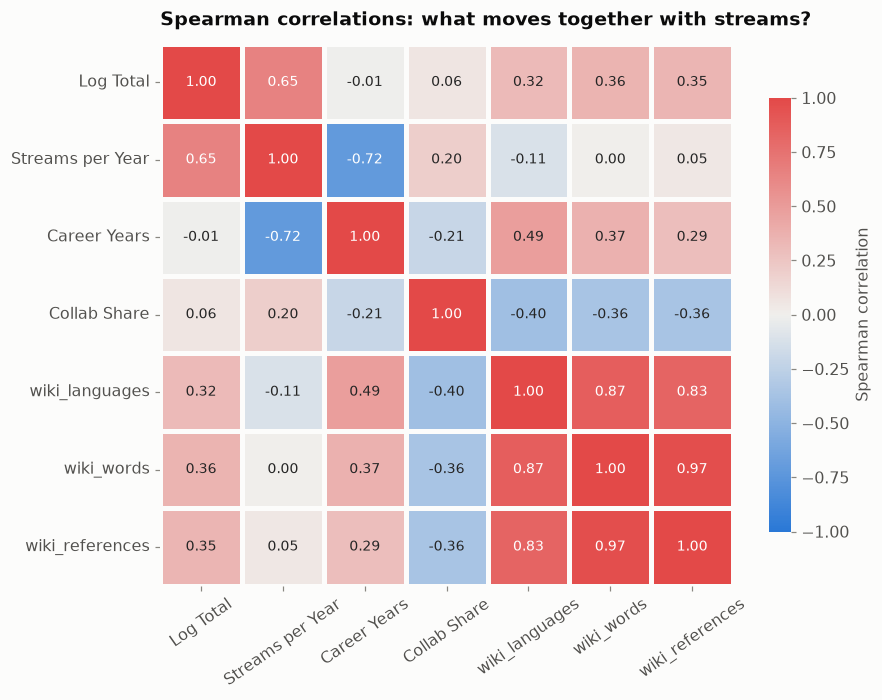

,rho,p-value
variable,,
Career Years,-0.012,0.781
Collab Share,0.062,0.163
wiki_languages,0.318,0.000
wiki_words,0.359,0.000
wiki_references,0.349,0.000


In [65]:
corr_cols = ['Log Total', 'Streams per Year', 'Career Years', 'Collab Share', 'wiki_languages', 'wiki_words', 'wiki_references']
corr = lab[corr_cols].corr(method='spearman')

diverging = LinearSegmentedColormap.from_list('blue_gray_red', [BLUE, '#f0efec', RED])
fig, ax = plt.subplots(figsize=(8.4, 6.4))
sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 9}, linewidths=2,
            linecolor=SURFACE, cbar_kws={'label': 'Spearman correlation', 'shrink': 0.8}, ax=ax)
ax.set_title('Spearman correlations: what moves together with streams?')
ax.tick_params(axis='x', rotation=35)
ax.grid(False)
save(fig, 'p3_correlations')
plt.show()

drivers = pd.DataFrame([dict(zip(['rho', 'p-value'], stats.spearmanr(lab[c], lab['Total Streams'], nan_policy='omit')), variable=c)
                        for c in ['Career Years', 'Collab Share', 'wiki_languages', 'wiki_words', 'wiki_references']])
drivers.set_index('variable').round(3)

* As in Part 1, **career length and Collab Share do not move with total streams** (ρ ≈ 0).
* **The three Wikipedia variables are the only ones clearly linked with streams** (ρ = 0.32-0.36, all p < 0.001): the more the world writes about an artist, and in more languages, the more they are streamed.
* They are strongly linked to each other (0.83-0.97), so they measure the same thing: **public attention**.
* They also rise with career length (0.49 for languages) and fall with Collab Share (-0.40): plausibly because older artists have had decades to become famous worldwide, while very collaborative artists
  (often regional stars and producers) are written about less. This will matter in 3.3 and 3.4.
* Streams per Year is linked with the total (0.65) partly by construction (it is computed from it), so we do not read it as a cause.

In [66]:
# same genre groups and colours as the maps (MAP_COLORS, section 2.3)
lab['Map Genre'] = lab['Genre Family'].where(lab['Genre Family'].isin(list(MAP_COLORS)[:3]), 'Rock, EDM & other')
fig = px.scatter(lab.dropna(subset=['wiki_languages']), x='wiki_languages', y='Total (B)', log_x=True, log_y=True,
                 color='Map Genre', color_discrete_map=MAP_COLORS, category_orders={'Map Genre': list(MAP_COLORS)},
                 hover_name='Artist Name', hover_data={'wiki_languages': True, 'Total (B)': ':.1f', 'Map Genre': False,
                                                      'Primary Genre': True, 'Country of Origin': True},
                 labels={'wiki_languages': 'Wikipedia language editions (log scale)', 'Total (B)': 'Total streams, billions (log scale)'},
                 title='Global reach on Wikipedia vs total streams (hover for names)', height=560)
fig.update_traces(marker=dict(size=8, opacity=0.75, line=dict(width=1, color='white')))
fig.update_layout(legend=dict(title='Genre family', orientation='h', y=1.02, x=0, yanchor='bottom'))
fig.show()

small_footprint = lab[lab['wiki_languages'] <= 10]
print(f"Artists with articles in 10 languages or fewer: {len(small_footprint)}, of which Latin: {(small_footprint['Genre Family'] == 'Latin').sum()}")
small_footprint.nlargest(5, 'Total Streams')[['Artist Name', 'Primary Genre', 'wiki_languages', 'Total Streams']]

Artists with articles in 10 languages or fewer: 68, of which Latin: 52


,Artist Name,Primary Genre,wiki_languages,Total Streams
67,Fuerza Regida,Latin,6.0,27466.8
68,Junior H,Regional Mexican,3.0,27406.8
100,Natanael Cano,Regional Mexican,5.0,20300.7
107,Sech,Reggaeton,6.0,19528.3
110,Henrique & Juliano,Sertanejo,2.0,19231.7


The trend is clear but loose: for any number of language editions, streams vary a lot. Most of the artists with **small Wikipedia footprints but big totals are Latin** (aqua):
of the 68 artists with articles in 10 languages or fewer, 52 are Latin, e.g. Fuerza Regida (27.5 B streams, 6 languages), Junior H (27.4 B, 3), Natanael Cano (20.3 B, 5).
A plausible reading: they are streaming stars of a huge language market that English-language sources do not (yet) write much about.

### 3.3 Artist archetypes
Are all successful artists successful in the same way? We group artists with **k-means clustering** on five standardised variables that describe *how* they reached the top:
total streams, momentum (streams per year), collaboration share, career length and global reach (Wikipedia languages); total streams, momentum and Wikipedia languages
are taken on log scales because they are very skewed.
Standardising (mean 0, standard deviation 1) is needed so that no variable dominates just because of its units.
(Momentum is itself total streams divided by career length, so time counts a little more than the other dimensions. We keep it on purpose:
it is what separates a new superstar from an artist who got there slowly.)

In [67]:
CLUSTER_VARS = ['Log Total', 'Log Streams per Year', 'Collab Share', 'Career Years', 'Log Wiki Languages']
cluster_input = lab[CLUSTER_VARS].fillna(lab[CLUSTER_VARS].median())      # median for the few artists without Wikipedia data
Z = StandardScaler().fit_transform(cluster_input)

rows = []
for k in range(2, 8):
    model_k = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)     # 20 random starts, keep the best
    rows.append({'k': k, 'silhouette': silhouette_score(Z, model_k.labels_), 'inertia': model_k.inertia_})
k_scores = pd.DataFrame(rows).set_index('k')
display(k_scores.round(3))

# What does the best-scoring split (k = 2) actually separate? Medians of each group:
two_groups = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(Z)
lab.groupby(two_groups)[['Total Streams', 'Career Years', 'Collab Share', 'wiki_languages']].median().round(0).rename_axis('k = 2 group')

,silhouette,inertia
k,,
2,0.316,1783.769
3,0.300,1296.513
4,0.287,1063.058
5,0.290,876.836
6,0.268,789.311
7,0.257,717.289


,Total Streams,Career Years,Collab Share,wiki_languages
k = 2 group,,,,
0,9291.0,37.0,8.0,69.0
1,13220.0,14.0,61.0,33.0


The silhouette score (how well separated the groups are, from -1 to 1) is highest for k = 2 (0.32) and a little lower for 3 to 5 (0.29-0.30), and the inertia (spread inside the groups)
keeps falling without a sharp "elbow". k = 2 only separates the long-career, low-collaboration artists from everyone else (table above), so we choose **k = 4**:
a little less separated, but it also distinguishes the superstars and the regional collaborators. A silhouette of about 0.3 tells us the groups overlap:
archetypes are tendencies, not sealed boxes. (Momentum is total streams divided by career length, so it partly repeats those two variables.)

In [68]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=42).fit(Z)
lab['cluster'] = kmeans.labels_

# Name the clusters from their profile (the numbers k-means gives are arbitrary)
profile = lab.groupby('cluster')[['Total Streams', 'Career Years', 'Collab Share', 'wiki_languages']].median()
names = {profile['Total Streams'].idxmax(): 'Superstars'}
names[profile.drop(index=list(names))['Career Years'].idxmax()] = 'Legacy acts'
names[profile.drop(index=list(names))['wiki_languages'].idxmin()] = 'Regional collaborators'
names[profile.drop(index=list(names)).index[0]] = 'Streaming-era core'
lab['Archetype'] = lab['cluster'].map(names)

# Is the grouping stable? Re-run k-means with 10 other random seeds and compare (adjusted Rand index: 1 = the same groups)
agreement = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=4, n_init=20, random_state=seed).fit_predict(Z)) for seed in range(10)]
print(f'Agreement with 10 re-runs: lowest {min(agreement):.2f}, average {np.mean(agreement):.2f}')

ARCHETYPE_COLORS = {'Superstars': BLUE, 'Legacy acts': ORANGE, 'Regional collaborators': AQUA, 'Streaming-era core': GRAY}
archetypes = (lab.groupby('Archetype')
                 .agg(artists=('Artist ID', 'size'), median_total=('Total Streams', 'median'),
                      median_per_year=('Streams per Year', 'median'), median_collab=('Collab Share', 'median'),
                      median_career=('Career Years', 'median'), median_wiki_languages=('wiki_languages', 'median'),
                      pct_groups=('Artist Type', lambda s: (s == 'Group').mean() * 100),
                      pct_non_english=('Language Group', lambda s: (s != 'English').mean() * 100))
                 .loc[list(ARCHETYPE_COLORS)])
examples = lab.sort_values('Total Streams', ascending=False).groupby('Archetype')['Artist Name'].apply(lambda s: ', '.join(s.head(6)))
display(archetypes.assign(median_total=archetypes['median_total'].map(billions),
                          median_per_year=archetypes['median_per_year'].map(billions)).round(1))
examples.loc[list(ARCHETYPE_COLORS)].to_frame('biggest artists')

Agreement with 10 re-runs: lowest 1.00, average 1.00


,artists,median_total,median_per_year,median_collab,median_career,median_wiki_languages,pct_groups,pct_non_english
Archetype,,,,,,,,
Superstars,103,31.2B,2.1B,56.3,15.0,57.0,13.6,20.4
Legacy acts,91,9.9B,0.3B,3.7,42.0,71.0,58.2,22.0
Regional collaborators,75,10.1B,0.8B,86.2,12.0,6.0,25.3,98.7
Streaming-era core,231,10.9B,0.7B,55.7,16.0,36.0,17.7,19.5


,biggest artists
Archetype,
Superstars,"Drake, Taylor Swift, Bad Bunny, The Weeknd, Justin Bieber, Ariana Grande"
Legacy acts,"Queen, The Beatles, Michael Jackson, Die drei ???, Disney, Red Hot Chili Peppers"
Regional collaborators,"Junior H, Arcángel, Natanael Cano, Sech, Henrique & Juliano, JHAYCO"
Streaming-era core,"Diplo, Snoop Dogg, 50 Cent, Mac Miller, Quavo, Don Omar"


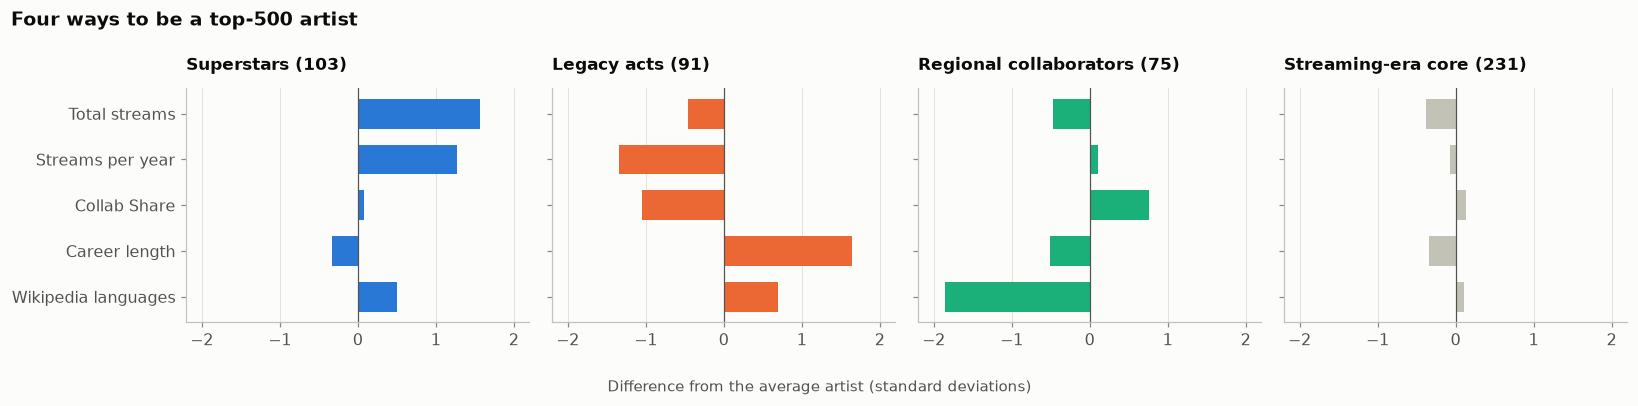

In [69]:
# How each archetype differs from the average artist, in standard deviations (0 = average)
z_profile = pd.DataFrame(Z, columns=CLUSTER_VARS).groupby(lab['Archetype']).mean().loc[list(ARCHETYPE_COLORS)]
labels = ['Total streams', 'Streams per year', 'Collab Share', 'Career length', 'Wikipedia languages']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True, sharey=True)
for ax, (name, row) in zip(axes, z_profile.iterrows()):
    ax.barh(labels[::-1], row.values[::-1], color=ARCHETYPE_COLORS[name], height=0.65)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(f"{name} ({archetypes.loc[name, 'artists']})", fontsize=11)
    ax.grid(axis='y', visible=False)
axes[0].set_xlim(-2.2, 2.2)
fig.supxlabel('Difference from the average artist (standard deviations)', fontsize=10, color=INK_2)
fig.suptitle('Four ways to be a top-500 artist', x=0.01, ha='left', fontweight='bold', color=INK)
fig.tight_layout()
save(fig, 'p3_archetypes')
plt.show()

In [70]:
fig = px.scatter(lab, x='Career Years', y='Total (B)', log_y=True, color='Archetype',
                 color_discrete_map=ARCHETYPE_COLORS, category_orders={'Archetype': list(ARCHETYPE_COLORS)},
                 hover_name='Artist Name', hover_data={'Primary Genre': True, 'Country of Origin': True, 'Collab Share': ':.0f',
                                                      'wiki_languages': True, 'Archetype': False, 'Total (B)': ':.1f'},
                 labels={'Career Years': 'Career length (years)', 'Total (B)': 'Total streams, billions (log scale)',
                         'Collab Share': 'Collab share (%)', 'wiki_languages': 'Wikipedia languages'},
                 title='Artist archetypes (hover for names, click the legend to hide a group)', height=560)
fig.update_traces(marker=dict(size=8, opacity=0.8, line=dict(width=1, color='white')))
fig.update_layout(legend=dict(title='', orientation='h', y=1.02, x=0, yanchor='bottom'))
fig.write_html(MAP_DIR.parent / 'archetypes.html', include_plotlyjs='cdn')
fig.show()

**A four-group description of the top 500.** (k-means always returns as many groups as we ask for, so this is a useful summary of the data rather than proof that exactly four
types exist; the groups are stable across random starts, but they overlap.)

| Archetype | Size | What defines it | Examples |
|---|---|---|---|
| **Superstars** | 103 | Median 31 B streams (3x the others) and 2.1 B per year; average collaboration; 80 % sing in English | Drake, Taylor Swift, Bad Bunny, The Weeknd |
| **Legacy acts** | 91 | Careers of 42 years, almost no collaborations (4 %), 58 % groups, the **largest global reach** (71 Wikipedia languages) but fewer streams (9.9 B) | Queen, The Beatles, Michael Jackson |
| **Regional collaborators** | 75 | 99 % non-English, 86 % of streams from collaborations, short careers (12 years) and **tiny global reach** (6 languages) | Junior H, Natanael Cano, Sech, Henrique & Juliano |
| **Streaming-era core** | 231 | Close to average on everything: 2000s-2010s artists with about 11 B streams | Diplo, Snoop Dogg, 50 Cent, Mac Miller |

Legacy acts stand out for **time and global fame**, regional collaborators for **collaboration inside a big language market**, superstars for **total streams and momentum**
(which is partly how the groups are defined).
Global fame and streaming success are clearly not the same thing: the most famous group (Legacy acts) is not the most streamed.

### 3.4 Stream estimator
Can we **estimate an artist's all-time streams** from their characteristics? We train models to predict `log10(Total Streams)` (the log makes the
skewed target better behaved, and errors become *relative*: being 20 % off counts the same for a small or a huge artist). We compare two sets of inputs:

* **A · Profile only**: genre family, region, language group, artist type, sex, debut year, collaboration share. Everything the dataset says about *who* the artist is.
* **B · Profile + Wikipedia footprint**: the same, plus the three Wikipedia variables (global reach and how much has been written about the artist).

and four models: a **baseline** that always predicts the average of the training artists (any useful model must beat it), **ridge regression** (a linear model), a **random forest**
and **gradient boosting** (both combine many decision trees and can capture non-linear effects). Every model is evaluated with **5-fold cross-validation repeated 3 times**:
it is always scored on artists it did not see during training, so the scores are honest.

In [71]:
PROFILE_CAT = ['Genre Family', 'Region', 'Language Group', 'Artist Type', 'Sex']
PROFILE_NUM = ['Debut Year', 'Collab Share']
FEATURE_SETS = {'A · profile only': PROFILE_NUM, 'B · profile + Wikipedia': PROFILE_NUM + WIKI_COLS}

X_all = lab[PROFILE_CAT + PROFILE_NUM + WIKI_COLS].astype({'Debut Year': float})
y_all = lab['Log Total']


def make_model(estimator, numeric, scale=False):
    """One-hot encode the categories, fill missing numbers with the median (and scale them for ridge), then fit."""
    numeric_steps = [SimpleImputer(strategy='median')] + ([StandardScaler()] if scale else [])
    prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), PROFILE_CAT),
                              ('numbers', make_pipeline(*numeric_steps), numeric)])
    return make_pipeline(prep, estimator)


MODELS = {
    'Baseline (mean)': (DummyRegressor(strategy='mean'), False),
    'Ridge regression': (RidgeCV(alphas=np.logspace(-2, 3, 30)), True),
    'Random forest': (RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=42, n_jobs=-1), False),
    'Gradient boosting': (HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42), False),
}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

results = []
for set_name, numeric in FEATURE_SETS.items():
    for model_name, (estimator, scale) in MODELS.items():
        scores = cross_validate(make_model(estimator, numeric, scale), X_all, y_all, cv=cv,
                                scoring=['neg_mean_absolute_error', 'r2'])
        mae = -scores['test_neg_mean_absolute_error'].mean()
        results.append({'inputs': set_name, 'model': model_name, 'MAE (log10)': mae, 'typical error': f'x{10 ** mae:.2f}',
                        'R²': scores['test_r2'].mean(), 'R² spread (sd over folds)': scores['test_r2'].std()})
results = pd.DataFrame(results)
results.round(3)

,inputs,model,MAE (log10),typical error,R²,R² spread (sd over folds)
0,A · profile only,Baseline (mean),0.193,x1.56,-0.025,0.037
1,A · profile only,Ridge regression,0.191,x1.55,-0.006,0.057
2,A · profile only,Random forest,0.195,x1.57,-0.020,0.104
3,A · profile only,Gradient boosting,0.195,x1.57,-0.048,0.109
4,B · profile + Wikipedia,Baseline (mean),0.193,x1.56,-0.025,0.037
5,B · profile + Wikipedia,Ridge regression,0.159,x1.44,0.295,0.121
6,B · profile + Wikipedia,Random forest,0.163,x1.46,0.294,0.113
7,B · profile + Wikipedia,Gradient boosting,0.155,x1.43,0.346,0.110


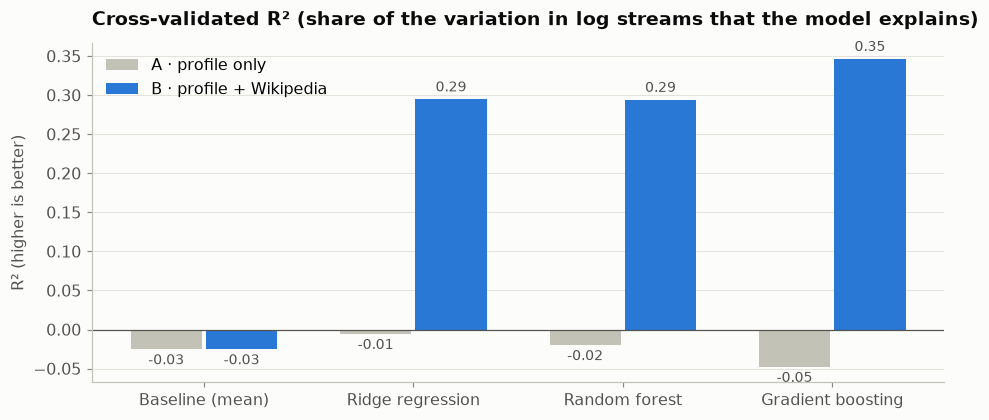

In [72]:
fig, ax = plt.subplots(figsize=(10, 4))
pivot = results.pivot(index='model', columns='inputs', values='R²').loc[list(MODELS)]
x = np.arange(len(pivot))
for i, (col, color) in enumerate(zip(pivot.columns, [GRAY, BLUE])):
    bars = ax.bar(x + (i - 0.5) * 0.36, pivot[col], width=0.34, color=color, label=col)
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in pivot[col]], padding=3, fontsize=9, color=INK_2)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_xticks(x, pivot.index)
ax.set(title='Cross-validated R² (share of the variation in log streams that the model explains)', ylabel='R² (higher is better)')
ax.legend(loc='upper left')
ax.grid(axis='x', visible=False)
save(fig, 'p3_model_comparison')
plt.show()

* **With the profile alone, no model does meaningfully better than the baseline** (which always predicts the average): every R² is at or below 0, and the typical
  errors (x1.55-1.57) are within 0.01 of the baseline's (x1.56). Genre, region, language, type, sex, debut year and collaboration style tell us almost nothing about *how big* a top-500 artist is
  (artist type does differ between groups, Insight 2, but it adds little predictive power). This confirms Part 1 with a stronger, multivariate test.
* **Adding the Wikipedia footprint helps every trained model**: R² rises to 0.29-0.35 and the typical error falls to x1.43-1.46 (for gradient boosting, an estimate is usually
  within -30 %/+43 % of the truth).
* The three trained models are close: their R² differ by less than the spread between folds (standard deviation about 0.11-0.12), so we do not claim one is truly better.
  We use gradient boosting, which has the best average; since it was chosen on these same scores, its R² of 0.35 may be slightly optimistic. About two thirds of the variation
  remains unexplained: which artist becomes *bigger* inside the top 500 depends on things this data cannot see (the songs themselves, marketing, timing, luck).

Best model (inputs B): Gradient boosting


Increase in error when shuffled: Wikipedia (3 variables) 0.107, Debut Year 0.035, Collab Share 0.009, Genre Family 0.009, Sex 0.006, Region 0.003, Language Group 0.003, Artist Type 0.001


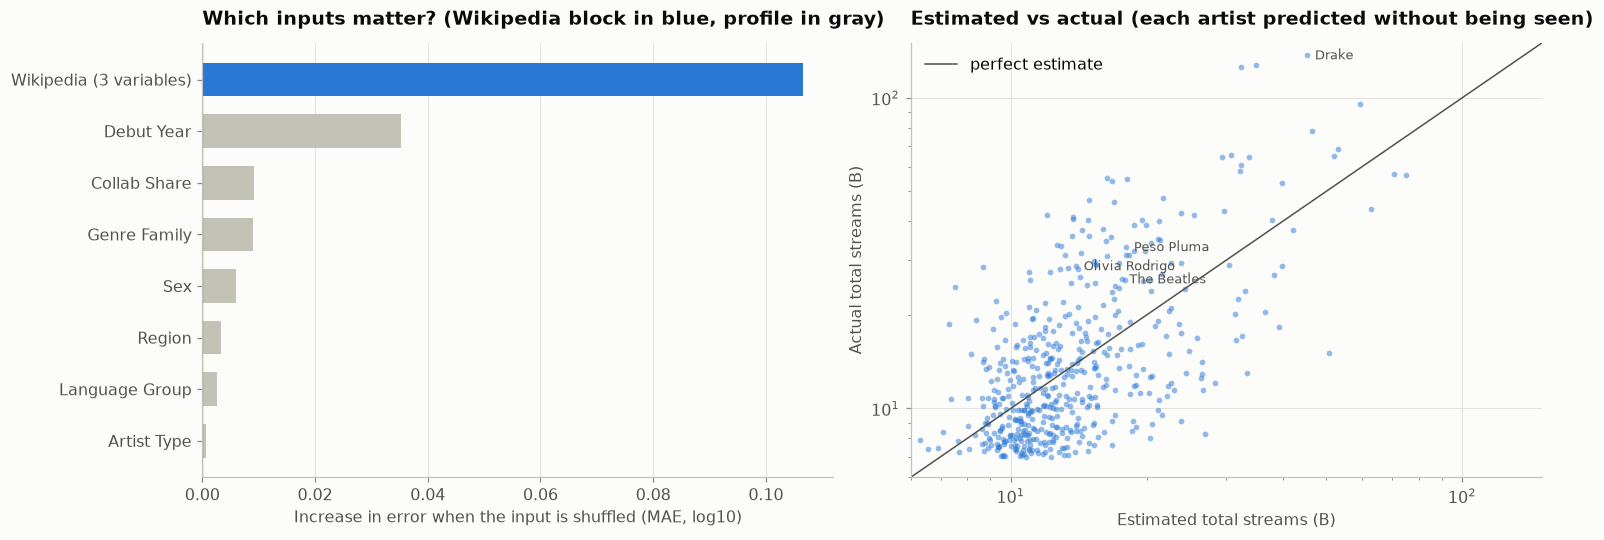

In [73]:
best_name = results[results['inputs'].str.startswith('B')].sort_values('MAE (log10)').iloc[0]['model']
print('Best model (inputs B):', best_name)


def make_best_model():
    """A fresh, untrained copy of the best model with inputs B."""
    estimator, scale = MODELS[best_name]
    return make_model(estimator, FEATURE_SETS['B · profile + Wikipedia'], scale)


# "Out-of-fold" predictions: each artist is predicted by a model trained on the other 80 % (it never saw that artist)
oof_pred = cross_val_predict(make_best_model(), X_all, y_all, cv=KFold(5, shuffle=True, random_state=42))
residual = y_all - oof_pred
LOW_Q, HIGH_Q = np.quantile(residual, [0.1, 0.9])      # used for the 80 % range of the estimator below

# Permutation importance: shuffle an input (breaking its link with the target) and measure how much worse the predictions get
# on artists the model did not see. The three Wikipedia variables are almost the same information (correlations 0.83-0.97),
# so shuffling one alone would let the model use the other two instead: we shuffle them together, as one block.
INPUT_GROUPS = {c: [c] for c in PROFILE_CAT + PROFILE_NUM} | {'Wikipedia (3 variables)': WIKI_COLS}


def group_importance(model, X, y, groups, n_repeats=10, seed=42):
    """Average increase in MAE when the columns of each group are shuffled together."""
    rng = np.random.default_rng(seed)
    base_error = np.mean(np.abs(y - model.predict(X)))
    increase = {}
    for name, cols in groups.items():
        errors = []
        for _ in range(n_repeats):
            X_shuffled = X.copy()
            X_shuffled[cols] = X[cols].to_numpy()[rng.permutation(len(X))]       # same shuffle for all columns of the group
            errors.append(np.mean(np.abs(y - model.predict(X_shuffled))))
        increase[name] = np.mean(errors) - base_error
    return pd.Series(increase)


importances = []
for train_idx, test_idx in KFold(5, shuffle=True, random_state=42).split(X_all):
    model = make_best_model().fit(X_all.iloc[train_idx], y_all.iloc[train_idx])
    importances.append(group_importance(model, X_all.iloc[test_idx], y_all.iloc[test_idx], INPUT_GROUPS))
importance = pd.concat(importances, axis=1).mean(axis=1).sort_values()
print('Increase in error when shuffled:', ', '.join(f'{name} {value:.3f}' for name, value in importance.sort_values(ascending=False).items()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
ax1.barh(importance.index, importance.values, color=[BLUE if c.startswith('Wikipedia') else GRAY for c in importance.index], height=0.65)
ax1.axvline(0, color=INK_2, linewidth=0.8)
ax1.set(title='Which inputs matter? (Wikipedia block in blue, profile in gray)', xlabel='Increase in error when the input is shuffled (MAE, log10)')
ax1.grid(axis='y', visible=False)

ax2.scatter(10 ** oof_pred / 1000, lab['Total Streams'] / 1000, s=14, color=BLUE, alpha=0.5, linewidths=0)
lims = [6, 150]
ax2.plot(lims, lims, color=INK_2, linewidth=1, label='perfect estimate')
ax2.set(xscale='log', yscale='log', xlim=lims, ylim=lims, title='Estimated vs actual (each artist predicted without being seen)',
        xlabel='Estimated total streams (B)', ylabel='Actual total streams (B)')
for name in ['Drake', 'The Beatles', 'Peso Pluma', 'Olivia Rodrigo']:
    i = lab.index[lab['Artist Name'] == name][0]
    ax2.annotate(name, (10 ** oof_pred[i] / 1000, lab.at[i, 'Total Streams'] / 1000), xytext=(5, -3),
                 textcoords='offset points', fontsize=8.5, color=INK_2)
ax2.legend(loc='upper left')
save(fig, 'p3_importance_and_fit')
plt.show()

* Shuffled together, the **three Wikipedia variables matter most by far**: the error rises by 0.107, about 3 times more than for **Debut Year** (0.035), the second input;
  every other input adds little. Debut Year matters here although on its own it predicted nothing (model A); the next cell looks at why.
* The right-hand plot shows the model's limits: it **underestimates the superstars** (Drake, at the top right, and the two points just below him, Taylor Swift and Bad Bunny,
  sit far above the line). The estimates are pulled towards the middle, which is typical when the extremes are rare.

In [74]:
# Does debut year add information once fame is known? Wikipedia languages alone vs together with Debut Year (same model and cross-validation)
for inputs in (['wiki_languages'], ['wiki_languages', 'Debut Year']):
    r2 = cross_validate(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
                        X_all[inputs], y_all, cv=cv, scoring='r2')['test_score'].mean()
    print(f'R² with {inputs}: {r2:.2f}')

famous = lab[lab['wiki_languages'] >= 60]
print('\nMedian total streams of artists with articles in 60+ languages:')
famous.groupby(np.where(famous['Debut Year'] < 1990, 'debuted before 1990', 'debuted 1990 or later'))['Total Streams'].median().map(billions).to_frame('median total streams')

R² with ['wiki_languages']: -0.00


R² with ['wiki_languages', 'Debut Year']: 0.14

Median total streams of artists with articles in 60+ languages:


,median total streams
debuted 1990 or later,17.9B
debuted before 1990,10.7B


**Debut year adds information once fame is known.** In this model, Wikipedia languages alone explain nothing (R² ≈ 0), but with Debut Year added R² = 0.14; and among
artists with articles in 60+ languages, those who debuted before 1990 have a median of 10.7 B streams, those who debuted later 17.9 B. So, for the same fame, earlier debuts
go with fewer streams. This test cannot tell whether the two variables interact or simply add up, and it shows a pattern, not its cause (our interpretation: an old act's fame was built before streaming).

**Who streams more (or less) than their fame suggests?** The gap between actual and estimated streams is itself informative: a positive gap means
the artist gets more streams than artists with a similar profile and Wikipedia footprint.

In [75]:
lab['Actual / Estimated'] = 10 ** residual
cols = ['Artist Name', 'Primary Genre', 'Country of Origin', 'Archetype', 'wiki_languages', 'Actual / Estimated']
over = lab.nlargest(8, 'Actual / Estimated')[cols]
under = lab.nsmallest(8, 'Actual / Estimated')[cols]
fmt = {'wiki_languages': '{:.0f}', 'Actual / Estimated': '{:.2f}x'}
display(over.style.format(fmt, na_rep='-').set_caption('Stream much MORE than expected'))
display(under.style.format(fmt, na_rep='-').set_caption('Stream much LESS than expected'))
lab.groupby('Archetype')['Actual / Estimated'].median().loc[list(ARCHETYPE_COLORS)].round(2).to_frame('median actual / estimated')

,Artist Name,Primary Genre,Country of Origin,Archetype,wiki_languages,Actual / Estimated
2,Bad Bunny,Reggaeton,United States,Superstars,60,3.90x
1,Taylor Swift,Pop,United States,Superstars,155,3.65x
24,David Guetta,EDM,France,Superstars,89,3.50x
14,Post Malone,Pop,United States,Superstars,55,3.38x
63,Pritam,Pop,India,Superstars,23,3.29x
81,Die drei ???,Spoken Word,Germany,Legacy acts,-,3.28x
16,Future,Hip-Hop,United States,Superstars,39,3.22x
19,Coldplay,Rock,United Kingdom,Superstars,93,3.14x


,Artist Name,Primary Genre,Country of Origin,Archetype,wiki_languages,Actual / Estimated
169,Kid Cudi,Hip-Hop,United States,Streaming-era core,42,0.30x
408,6ix9ine,Hip-Hop,United States,Streaming-era core,49,0.31x
355,Jennifer Lopez,Pop,United States,Streaming-era core,119,0.38x
224,Becky G,Latin,United States,Streaming-era core,48,0.39x
421,JENNIE,K-Pop,South Korea,Streaming-era core,76,0.40x
248,Kesha,Pop,United States,Streaming-era core,82,0.43x
264,Paramore,Rock,United States,Legacy acts,139,0.43x
365,Jonas Brothers,Pop,United States,Streaming-era core,66,0.43x


,median actual / estimated
Archetype,
Superstars,1.71
Legacy acts,0.84
Regional collaborators,0.97
Streaming-era core,0.84


These are readings of the most extreme gaps; with R² = 0.35 a good part of every gap is simply noise, so they should not be over-interpreted.

* The biggest **over-performers are the superstars** (Bad Bunny 3.9x, Taylor Swift 3.7x, David Guetta, Post Malone, Coldplay): the model pulls its estimates towards the middle, so the very top is always underestimated.
  Pritam (a Bollywood composer, 3.3x) is a different case, probably because Indian film music is huge on streaming but little covered by English-language sources (our interpretation).
* Our reading of the **under-performers**: they are **famous for more than streaming hits**: Jennifer Lopez (articles in 119 languages, also a film star), 6ix9ine and Kid Cudi (heavy media attention), and artists whose peak came
  before or at the start of streaming (Kesha, Paramore, the Jonas Brothers).
* By archetype, Superstars stream 1.7x their estimate, Legacy acts and the Streaming-era core 0.84x. (This is partly circular: the archetypes were built using total streams,
  so the group with the biggest totals is naturally the one the model underestimates most.)

**The estimator.** Below, the final model is trained on all 500 artists. `estimate_streams` takes an artist profile and returns the estimate with an
**80 % range** (from the cross-validated errors: 8 out of 10 artists fall inside it). `estimate_from_wikipedia` goes one step further: it **scrapes
the artist's Wikipedia article live** (with the functions of Part 2) to get the footprint, so it can be applied to artists who are *not* in the dataset.
(Caution: the model only knows the top 500, all with about 7 billion streams or more, so its estimates only make sense for artists already in that range;
and the live match can be wrong for namesakes, so the function prints which article it used and warns when the match could not be confirmed.)

In [76]:
final_model = make_best_model().fit(X_all, y_all)


def estimate_streams(genre_family, region, language_group, artist_type, sex, debut_year, collab_share,
                     wiki_languages, wiki_words, wiki_references):
    """Estimated all-time streams (in billions) with an 80 % range."""
    row = pd.DataFrame([{'Genre Family': genre_family, 'Region': region, 'Language Group': language_group,
                         'Artist Type': artist_type, 'Sex': sex, 'Debut Year': float(debut_year), 'Collab Share': collab_share,
                         'wiki_languages': wiki_languages, 'wiki_words': wiki_words, 'wiki_references': wiki_references}])
    log_estimate = final_model.predict(row[X_all.columns])[0]
    return {'estimate': 10 ** log_estimate / 1000, 'low (80%)': 10 ** (log_estimate + LOW_Q) / 1000,
            'high (80%)': 10 ** (log_estimate + HIGH_Q) / 1000}


def estimate_from_wikipedia(name, genre_family, region, language_group, artist_type, sex, debut_year, collab_share,
                            country=None, genre=None):
    """Find the artist's Wikipedia article (Part 2 functions), read its footprint, and estimate streams."""
    soup, url, method = find_artist_page(name, country, genre)
    if soup is None:
        raise ValueError(f'No Wikipedia article found for {name!r}')
    if 'not confirmed' in method:
        print('Warning: this article could not be confirmed as the right artist (check it before trusting the estimate).')
    footprint = article_features(soup)
    print(f"Article: {page_title(soup)} (found by: {method}) | languages: {footprint['wiki_languages']} | "
          f"words: {footprint['wiki_words']:,} | references: {footprint['wiki_references']}")
    return estimate_streams(genre_family, region, language_group, artist_type, sex, debut_year, collab_share,
                            footprint['wiki_languages'], footprint['wiki_words'], footprint['wiki_references'])


def show(estimate):
    print(f"Estimated all-time streams: {estimate['estimate']:.1f}B  (80% range: {estimate['low (80%)']:.1f}B - {estimate['high (80%)']:.1f}B)")


# Example 1: a profile typed by hand - a Spanish-singing solo male Latin artist from the 2010s with a big Wikipedia footprint
show(estimate_streams('Latin', 'Latin America & Caribbean', 'Spanish', 'Solo', 'Male', 2015, 70,
                      wiki_languages=60, wiki_words=15000, wiki_references=250))
# Example 2: the same profile with a small footprint - the estimate drops
show(estimate_streams('Latin', 'Latin America & Caribbean', 'Spanish', 'Solo', 'Male', 2015, 70,
                      wiki_languages=8, wiki_words=2500, wiki_references=40))

Estimated all-time streams: 33.2B  (80% range: 20.0B - 62.1B)
Estimated all-time streams: 9.9B  (80% range: 6.0B - 18.6B)


In [77]:
# Example 3: live estimate for an artist scraped from Wikipedia right now (needs internet)
if ONLINE:
    actual = lab.loc[lab['Artist Name'] == 'Olivia Rodrigo', 'Total Streams'].iloc[0]
    show(estimate_from_wikipedia('Olivia Rodrigo', 'Pop', 'North America', 'English', 'Solo', 'Female', 2021, 10,
                                 country='United States', genre='Pop'))
    print(f'Actual: {billions(actual)}  (she is in the training data, so this is only a sanity check)')
else:
    print('No internet connection: live example skipped.')

Article: Olivia Rodrigo (found by: direct) | languages: 77 | words: 17,463 | references: 260
Estimated all-time streams: 19.7B  (80% range: 11.8B - 36.8B)
Actual: 28.8B  (she is in the training data, so this is only a sanity check)


**Interactive version.** In a running Jupyter session, the controls below update the estimate immediately (in a static view of the notebook, such as a PDF, they do not appear).

In [78]:
if widgets is not None:
    @widgets.interact(genre_family=sorted(lab['Genre Family'].unique()), region=list(REGIONS),
                      language_group=['English', 'Spanish', 'Other'], artist_type=['Solo', 'Group'],
                      sex=['Male', 'Female', 'Unknown'], debut_year=(1960, 2024), collab_share=(0, 100, 5),
                      wiki_languages=(1, 150), wiki_words=(500, 40000, 500), wiki_references=(0, 800, 10))
    def estimator_ui(genre_family='Pop', region='North America', language_group='English', artist_type='Solo', sex='Female',
                     debut_year=2015, collab_share=40, wiki_languages=40, wiki_words=8000, wiki_references=150):
        show(estimate_streams(genre_family, region, language_group, artist_type, sex, debut_year, collab_share,
                              wiki_languages, wiki_words, wiki_references))
else:
    print('ipywidgets is not installed: use estimate_streams(...) as in the examples above.')

interactive(children=(Dropdown(description='genre_family', index=3, options=('Hip-Hop & R&B', 'Latin', 'Other …

### 3.5 Artist comparison tool
Finally, a small tool to **compare artists**. `compare_artists` shows where two artists stand among the 500 (percentile 90 = better than 90 % of the list) on the
variables that matter, and `closest_peers` finds the artists with the most similar success profile (the same five standardised variables as the archetypes,
plus genre family), a recommendation-style "if you are interested in X, look at Y".

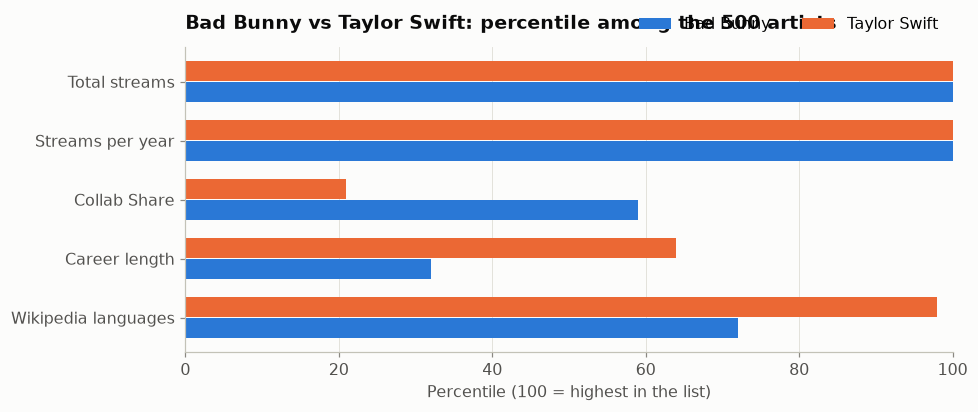

Artist Name,Bad Bunny,Taylor Swift
Total streams,100.0,100.0
Streams per year,100.0,100.0
Collab Share,59.0,21.0
Career length,32.0,64.0
Wikipedia languages,72.0,98.0


In [79]:
COMPARE = {'Total streams': 'Total Streams', 'Streams per year': 'Streams per Year', 'Collab Share': 'Collab Share',
           'Career length': 'Career Years', 'Wikipedia languages': 'wiki_languages'}
percentiles = pd.DataFrame({label: lab[col].rank(pct=True) * 100 for label, col in COMPARE.items()})
percentiles.index = lab['Artist Name']


def compare_artists(a, b):
    """Percentile of two artists on each variable, as a table and a chart."""
    table = percentiles.loc[[a, b]].T.astype(float).round(0)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    y = np.arange(len(table))
    for i, (artist, color) in enumerate(zip([a, b], [BLUE, ORANGE])):
        ax.barh(y + (0.5 - i) * 0.36, table[artist], height=0.34, color=color, label=artist)
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set(title=f'{a} vs {b}: percentile among the 500 artists', xlabel='Percentile (100 = highest in the list)')
    ax.legend(loc='lower right', ncols=2, bbox_to_anchor=(1, 1.0))
    ax.grid(axis='y', visible=False)
    plt.show()
    return table


peer_space = np.hstack([Z, pd.get_dummies(lab['Genre Family']).to_numpy(dtype=float)])
peer_finder = NearestNeighbors(n_neighbors=6).fit(peer_space)


def closest_peers(name, k=5):
    """The k artists with the most similar success profile."""
    i = lab.index[lab['Artist Name'] == name][0]
    _, idx = peer_finder.kneighbors(peer_space[[i]], n_neighbors=k + 1)
    peers = lab.iloc[idx[0][1:]]
    return peers[['Artist Name', 'Primary Genre', 'Country of Origin', 'Archetype']].assign(
        **{'Total Streams': peers['Total Streams'].map(billions), 'Collab Share': peers['Collab Share'].round(0)})


compare_artists('Bad Bunny', 'Taylor Swift')

In [80]:
closest_peers('Peso Pluma')

,Artist Name,Primary Genre,Country of Origin,Archetype,Total Streams,Collab Share
44,Myke Towers,Reggaeton,United States,Superstars,33.6B,72.0
42,Feid,Reggaeton,Colombia,Superstars,34.6B,71.0
27,Rauw Alejandro,Reggaeton,United States,Superstars,40.7B,74.0
67,Fuerza Regida,Latin,United States,Superstars,27.5B,58.0
28,Anuel AA,Reggaeton,United States,Superstars,40.5B,85.0


* **Bad Bunny vs Taylor Swift**: both are at the very top for total streams and momentum, but they got there differently. Bad Bunny relies much more on collaborations (59th percentile vs 21st for Taylor Swift),
  has a shorter career, and a smaller global reach on Wikipedia (72nd vs 98th percentile).
* **Peso Pluma's closest peers** are Myke Towers, Feid, Rauw Alejandro, Fuerza Regida and Anuel AA: young, very collaborative Spanish-language stars with similar momentum, exactly the artists
  someone interested in Peso Pluma (a fan, a label, a festival booker) would want to compare him with.

Both functions work for any artist in the data, e.g. `compare_artists('Drake', 'The Weeknd')` or `closest_peers('Coldplay')`.

## 4. Conclusions

### So, what makes a music artist successful?

**1 · Who dominates streaming.** The all-time top 500 is mostly **American** (53 % of the artists, 57 % of the streams), **English-speaking** (68 %), **Hip-Hop and Pop** (43 % together),
**solo** (75 %), and 78 % of the solo artists are men. Even inside this elite, streams are concentrated: the top 10 artists hold 10.6 % of all streams, and Drake alone has 11.5 times the median artist.

**2 · What does *not* go with being a bigger artist (inside the top 500).**
* **Career length**: no monotonic relationship with total streams (ρ ≈ 0; totals peak for careers of 10-19 years). Recent artists collect streams much faster; older ones got there slowly through their catalogue.
* **Collaborations**: how much an artist collaborates depends on the genre (2 % for Rock & Metal, 74 % for Latin), but *within* a genre we find no link between collaborating more and having more streams
  (a small effect cannot be ruled out). Most of the artists with 100 % collaborative streams are lyricists, producers and DJs, whose role is collaborative by nature.
* **Sex** (solo artists): women are under-represented (22 %), but their share stays about the same among the top 10, 50 and 100 (20-28 %), and we find no significant difference in their streams.
* **The whole profile together**: genre, region, language, type, sex, debut year and collaboration style, combined in a machine-learning model, predict hardly better than always guessing the average (R² ≤ 0).

**3 · What *does* go with being bigger.**
* **The streaming generation and solo artists dominate the list**: artists who debuted between 2000 and 2019 make up 76 % of the list and hold 80 % of its streams, and groups are rare
  at the very top (none in the top 10, 5 in the top 50). (This describes who is in the list; within the list, career length itself is not linked with totals.)
* **Public attention, read in its era**: the size of an artist's Wikipedia footprint (articles in many languages, long and well-sourced) is the only variable clearly linked with streams,
  and adding it to the profile lets a model explain about a third of the differences between artists (R² = 0.35, against ≤ 0 without it). Debut year adds information on top of it:
  for the same global fame, artists who debuted before 1990 have fewer streams (our interpretation: their fame was built before streaming).
* **A useful four-group description** (k-means): superstars stand out on total streams and momentum; legacy acts on decades of global fame and a catalogue; regional collaborators rise
  through collaborations inside big Spanish- and Portuguese-language markets, with almost no global media attention; and a large streaming-era core.

**4 · Where success comes from.** The maps show a handful of hubs. Counting areas (places within 25 km merged), Los Angeles and the San Juan area of Puerto Rico are practically level at the top,
ahead of London and New York City, and Medellín is the biggest area outside the US, the UK, Canada and Puerto Rico; how exactly a city is drawn changes the order. The newest artists of the list
are mostly non-English (79 % of the 2020s debuts, most of them Mexican acts), which suggests the top of streaming is becoming less English (a small group of 14, so a signal rather than proof).

**In one sentence:** inside the top 500, how big an artist is depends less on *who* they are (genre, country, sex, how often they collaborate) than on **how much attention** the world pays them,
read against **when** they became famous; and, judging by the newest artists in the list, that attention increasingly comes from outside the English-speaking world.

### Limitations
* **Only the top 500.** We compare successful artists with *other* successful artists. We cannot say what makes an artist *enter* the list: that would need data on less successful artists.
* **Correlation, not causation.** Wikipedia attention is both a cause and a consequence of streams; the estimator is a tool to *estimate* and *compare*, not proof of what *causes* success.
* **English Wikipedia** covers English-speaking artists better, which may partly explain why regional (Latin, Indian) artists look "less famous" than their streams.
* **Data quality.** The Lead/Feature split is unreliable for 33 artists (we used Solo/Collaborative instead), 10 artists have totals a year out of date, and "Debut Year" may be defined differently from Wikipedia's "Years active".
* **Birthplace vs origin.** 11 artists were born outside the country the dataset gives them; the map shows where they were born. Two Wikipedia place pages seem to carry inaccurate coordinates (section 2.2).
* **The scraper's rules** were checked on every artist in our data, but rules of thumb can fail on namesakes; `estimate_from_wikipedia` warns when it cannot confirm a match.

### Sources
* Dataset: `artist_streams.csv`, provided by the course (all-time most-streamed artists, 2026).
* Wikipedia (English), from the Main Page (https://en.wikipedia.org/wiki/Main_Page) and the artist and place articles reached through its search box, scraped in October 2026. Text available under CC BY-SA 4.0.
* Wikimedia's User-Agent policy (automated clients must identify themselves with a descriptive User-Agent): https://foundation.wikimedia.org/wiki/Policy:User-Agent_policy
* Wikipedia's style rule against linking very well-known places (why big cities need a search): https://en.wikipedia.org/wiki/Wikipedia:Manual_of_Style/Linking (MOS:OVERLINK)
* Methods: Gini coefficient from sorted values, https://en.wikipedia.org/wiki/Gini_coefficient ; golden-angle spiral (Vogel's model of sunflower seeds), https://en.wikipedia.org/wiki/Golden_angle ;
  kernel density estimation, https://en.wikipedia.org/wiki/Kernel_density_estimation ; haversine formula for distances on the globe, https://en.wikipedia.org/wiki/Haversine_formula ;
  Fisher's exact test, Kruskal-Wallis, Mann-Whitney and the hypergeometric distribution in SciPy (https://docs.scipy.org/doc/scipy/reference/stats.html);
  silhouette score, adjusted Rand index and k-means, https://scikit-learn.org/stable/modules/clustering.html
* Library documentation: pandas (https://pandas.pydata.org/docs/), Beautiful Soup (https://www.crummy.com/software/BeautifulSoup/bs4/doc/), Plotly maps (https://plotly.com/python/maps/),
  scikit-learn user guide on cross-validation, permutation importance and k-means (https://scikit-learn.org/stable/user_guide.html).